In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/OFTALMOLOGÍA.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 4:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]),
                          len(answer_positions["C"]), len(answer_positions["D"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 11 questions
Page 1, Q1 - A: Detected box: x0=75.4, y0=102.0, x1=134.5, y1=114.7
Page 1, Q1, A: Yellow pixels: 1219
Page 1, Q1, A: Total non-white pixels: 1430
Page 1, Q1, A: Yellow percentage: 85.2%


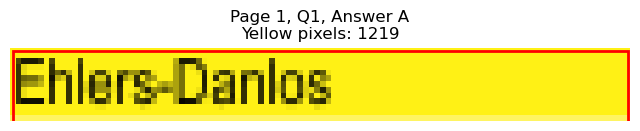

Page 1, Q1 - B: Detected box: x0=75.4, y0=114.6, x1=134.5, y1=127.3
Page 1, Q1, B: Yellow pixels: 110
Page 1, Q1, B: Total non-white pixels: 428
Page 1, Q1, B: Yellow percentage: 25.7%


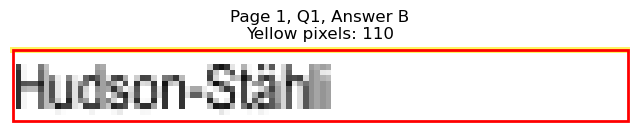

Page 1, Q1 - C: Detected box: x0=334.6, y0=102.0, x1=386.2, y1=114.7
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 231
Page 1, Q1, C: Yellow percentage: 0.0%


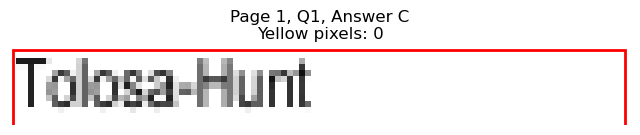

Page 1, Q1 - D: Detected box: x0=334.6, y0=114.6, x1=411.3, y1=127.3
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 393
Page 1, Q1, D: Yellow percentage: 0.0%


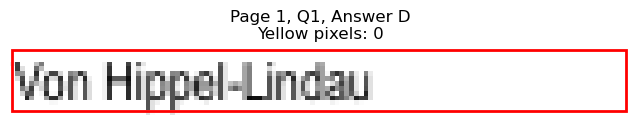


Page 1, Q1 - Selected Answer: A (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=75.4, y0=152.5, x1=196.2, y1=165.2
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 603
Page 1, Q2, A: Yellow percentage: 0.0%


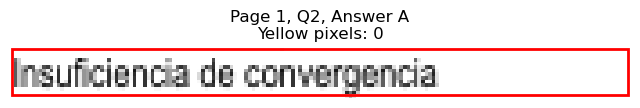

Page 1, Q2 - B: Detected box: x0=75.4, y0=165.1, x1=188.2, y1=177.8
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 578
Page 1, Q2, B: Yellow percentage: 0.0%


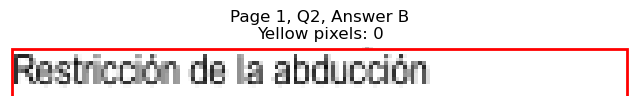

Page 1, Q2 - C: Detected box: x0=334.6, y0=152.5, x1=466.7, y1=165.2
Page 1, Q2, C: Yellow pixels: 1859
Page 1, Q2, C: Total non-white pixels: 2562
Page 1, Q2, C: Yellow percentage: 72.6%


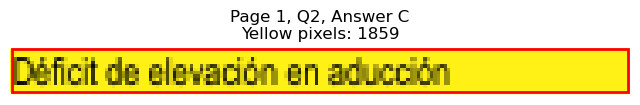

Page 1, Q2 - D: Detected box: x0=334.6, y0=165.1, x1=504.2, y1=177.8
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 1081
Page 1, Q2, D: Yellow percentage: 0.0%


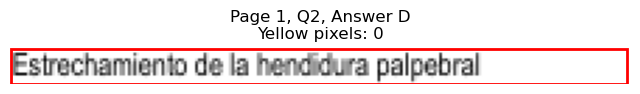


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=75.4, y0=202.9, x1=239.3, y1=215.6
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 839
Page 1, Q3, A: Yellow percentage: 0.0%


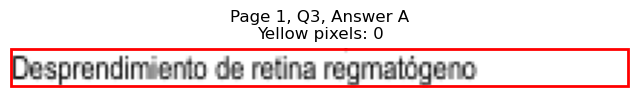

Page 1, Q3 - B: Detected box: x0=75.4, y0=215.7, x1=257.4, y1=228.3
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 939
Page 1, Q3, B: Yellow percentage: 0.0%


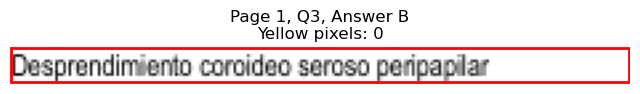

Page 1, Q3 - C: Detected box: x0=75.9, y0=228.3, x1=297.5, y1=240.9
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 1362
Page 1, Q3, C: Yellow percentage: 0.0%


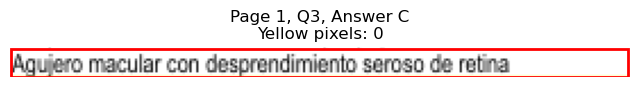

Page 1, Q3 - D: Detected box: x0=75.9, y0=240.9, x1=309.0, y1=253.5
Page 1, Q3, D: Yellow pixels: 2787
Page 1, Q3, D: Total non-white pixels: 3990
Page 1, Q3, D: Yellow percentage: 69.8%


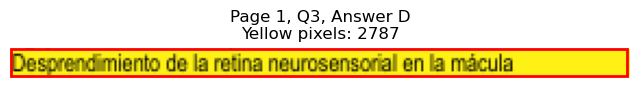


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=75.4, y0=291.4, x1=138.0, y1=304.1
Page 1, Q4, A: Yellow pixels: 114
Page 1, Q4, A: Total non-white pixels: 427
Page 1, Q4, A: Yellow percentage: 26.7%


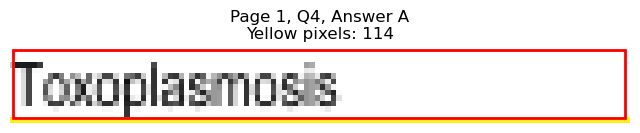

Page 1, Q4 - B: Detected box: x0=75.4, y0=304.0, x1=128.5, y1=316.7
Page 1, Q4, B: Yellow pixels: 1148
Page 1, Q4, B: Total non-white pixels: 1352
Page 1, Q4, B: Yellow percentage: 84.9%


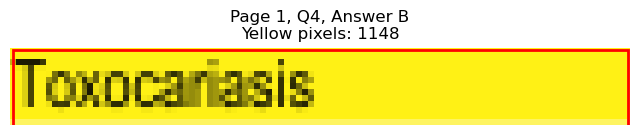

Page 1, Q4 - C: Detected box: x0=334.6, y0=291.4, x1=399.8, y1=304.1
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 341
Page 1, Q4, C: Yellow percentage: 0.0%


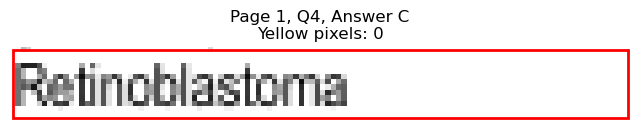

Page 1, Q4 - D: Detected box: x0=334.6, y0=304.0, x1=388.3, y1=316.7
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 271
Page 1, Q4, D: Yellow percentage: 0.0%


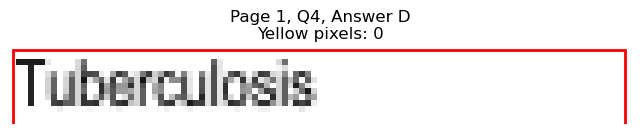


Page 1, Q4 - Selected Answer: B (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=75.4, y0=341.9, x1=136.1, y1=354.6
Page 1, Q5, A: Yellow pixels: 112
Page 1, Q5, A: Total non-white pixels: 389
Page 1, Q5, A: Yellow percentage: 28.8%


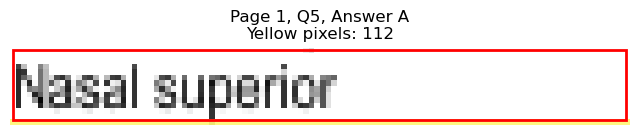

Page 1, Q5 - B: Detected box: x0=75.4, y0=354.5, x1=146.1, y1=367.2
Page 1, Q5, B: Yellow pixels: 1325
Page 1, Q5, B: Total non-white pixels: 1708
Page 1, Q5, B: Yellow percentage: 77.6%


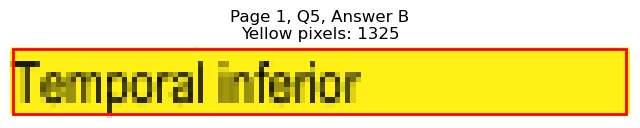

Page 1, Q5 - C: Detected box: x0=334.6, y0=341.9, x1=390.3, y1=354.6
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 295
Page 1, Q5, C: Yellow percentage: 0.0%


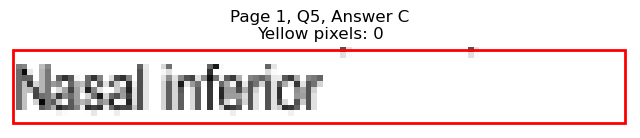

Page 1, Q5 - D: Detected box: x0=334.6, y0=354.5, x1=410.3, y1=367.2
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 382
Page 1, Q5, D: Yellow percentage: 0.0%


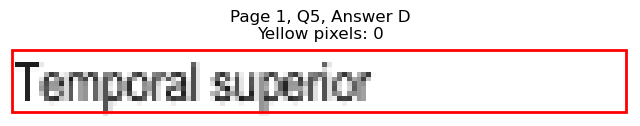


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=75.4, y0=392.3, x1=141.6, y1=405.0
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 327
Page 1, Q6, A: Yellow percentage: 0.0%


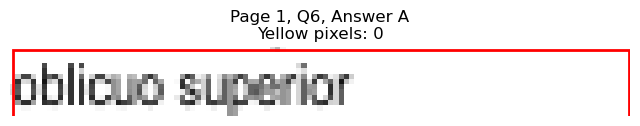

Page 1, Q6 - B: Detected box: x0=75.4, y0=404.9, x1=133.1, y1=417.6
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 266
Page 1, Q6, B: Yellow percentage: 0.0%


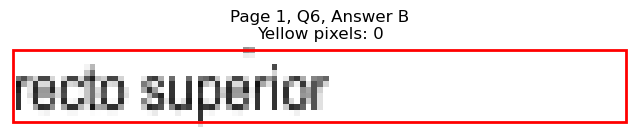

Page 1, Q6 - C: Detected box: x0=334.6, y0=392.3, x1=395.8, y1=405.0
Page 1, Q6, C: Yellow pixels: 0
Page 1, Q6, C: Total non-white pixels: 419
Page 1, Q6, C: Yellow percentage: 0.0%


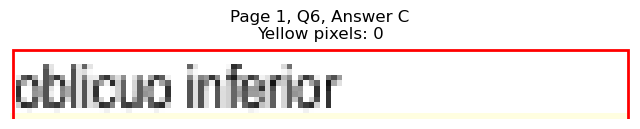

Page 1, Q6 - D: Detected box: x0=334.6, y0=404.9, x1=387.3, y1=417.6
Page 1, Q6, D: Yellow pixels: 1160
Page 1, Q6, D: Total non-white pixels: 1456
Page 1, Q6, D: Yellow percentage: 79.7%


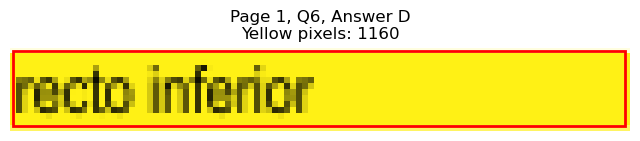


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=75.4, y0=455.5, x1=103.9, y1=468.1
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 146
Page 1, Q7, A: Yellow percentage: 0.0%


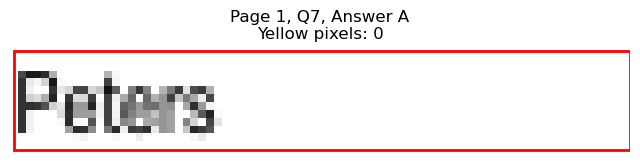

Page 1, Q7 - B: Detected box: x0=75.4, y0=468.1, x1=104.4, y1=480.7
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 163
Page 1, Q7, B: Yellow percentage: 0.0%


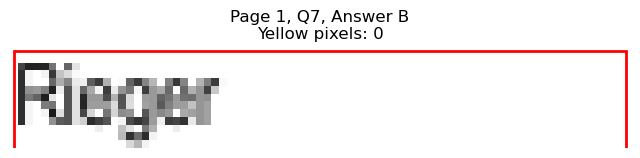

Page 1, Q7 - C: Detected box: x0=334.6, y0=455.5, x1=363.7, y1=468.1
Page 1, Q7, C: Yellow pixels: 80
Page 1, Q7, C: Total non-white pixels: 233
Page 1, Q7, C: Yellow percentage: 34.3%


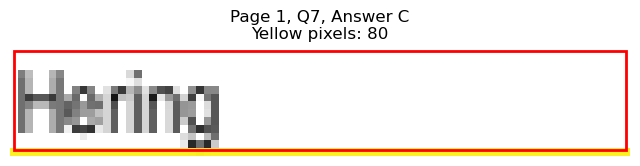

Page 1, Q7 - D: Detected box: x0=334.6, y0=468.1, x1=372.3, y1=480.7
Page 1, Q7, D: Yellow pixels: 1013
Page 1, Q7, D: Total non-white pixels: 1157
Page 1, Q7, D: Yellow percentage: 87.6%


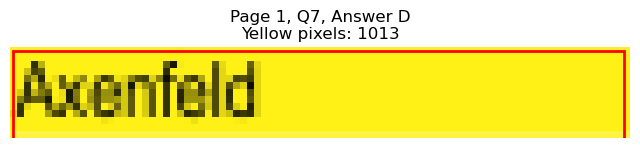


Page 1, Q7 - Selected Answer: D (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=75.4, y0=202.9, x1=183.8, y1=215.6
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 825
Page 1, Q8, A: Yellow percentage: 0.0%


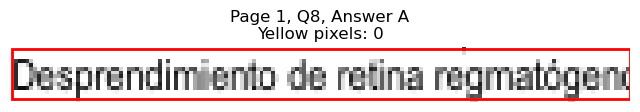

Page 1, Q8 - B: Detected box: x0=75.4, y0=543.8, x1=183.3, y1=556.4
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 549
Page 1, Q8, B: Yellow percentage: 0.0%


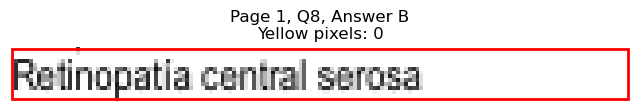

Page 1, Q8 - C: Detected box: x0=334.6, y0=531.2, x1=441.4, y1=543.8
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 705
Page 1, Q8, C: Yellow percentage: 0.0%


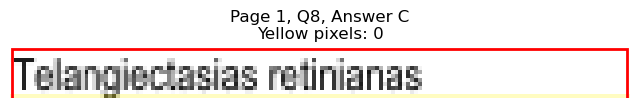

Page 1, Q8 - D: Detected box: x0=334.6, y0=543.8, x1=435.9, y1=556.4
Page 1, Q8, D: Yellow pixels: 1560
Page 1, Q8, D: Total non-white pixels: 2128
Page 1, Q8, D: Yellow percentage: 73.3%


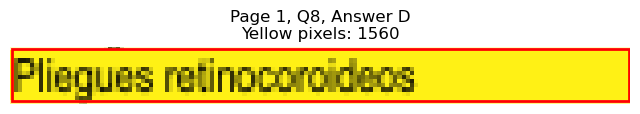


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=75.4, y0=581.7, x1=153.6, y1=594.4
Page 1, Q9, A: Yellow pixels: 129
Page 1, Q9, A: Total non-white pixels: 535
Page 1, Q9, A: Yellow percentage: 24.1%


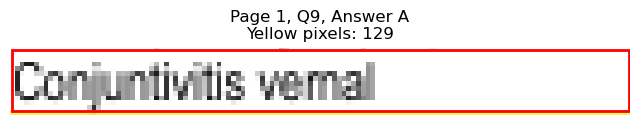

Page 1, Q9 - B: Detected box: x0=75.4, y0=594.3, x1=153.1, y1=607.0
Page 1, Q9, B: Yellow pixels: 1382
Page 1, Q9, B: Total non-white pixels: 1677
Page 1, Q9, B: Yellow percentage: 82.4%


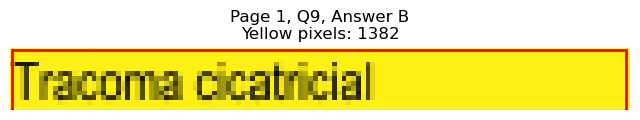

Page 1, Q9 - C: Detected box: x0=334.6, y0=581.7, x1=460.0, y1=594.4
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 664
Page 1, Q9, C: Yellow percentage: 0.0%


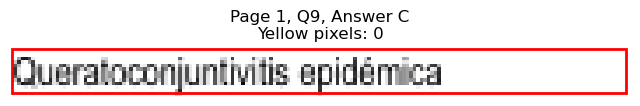

Page 1, Q9 - D: Detected box: x0=334.6, y0=594.3, x1=435.4, y1=607.0
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 539
Page 1, Q9, D: Yellow percentage: 0.0%


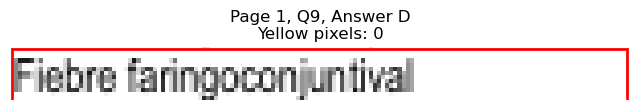


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=75.4, y0=644.9, x1=142.1, y1=657.5
Page 1, Q10, A: Yellow pixels: 1288
Page 1, Q10, A: Total non-white pixels: 1652
Page 1, Q10, A: Yellow percentage: 78.0%


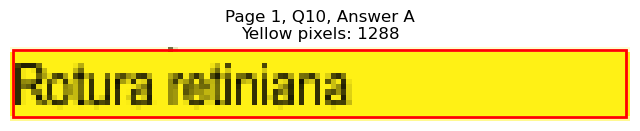

Page 1, Q10 - B: Detected box: x0=75.4, y0=657.5, x1=151.6, y1=670.1
Page 1, Q10, B: Yellow pixels: 127
Page 1, Q10, B: Total non-white pixels: 523
Page 1, Q10, B: Yellow percentage: 24.3%


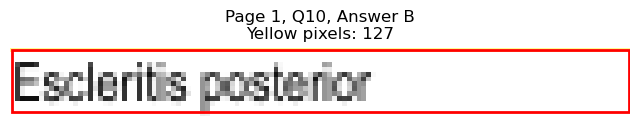

Page 1, Q10 - C: Detected box: x0=334.6, y0=644.9, x1=384.3, y1=657.5
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 288
Page 1, Q10, C: Yellow percentage: 0.0%


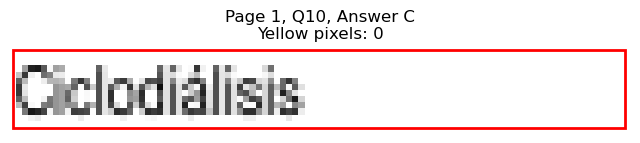

Page 1, Q10 - D: Detected box: x0=334.6, y0=657.5, x1=406.4, y1=670.1
Page 1, Q10, D: Yellow pixels: 0
Page 1, Q10, D: Total non-white pixels: 341
Page 1, Q10, D: Yellow percentage: 0.0%


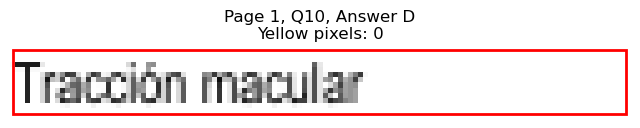


Page 1, Q10 - Selected Answer: A (based on yellow pixel count)




Page 1, Q11 - A: Detected box: x0=75.4, y0=695.4, x1=142.1, y1=708.0
Page 1, Q11, A: Yellow pixels: 0
Page 1, Q11, A: Total non-white pixels: 310
Page 1, Q11, A: Yellow percentage: 0.0%


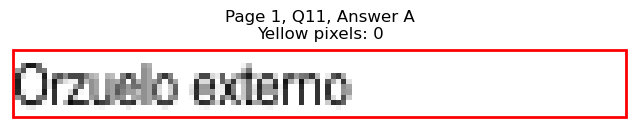

Page 1, Q11 - B: Detected box: x0=75.4, y0=708.0, x1=118.0, y1=720.6
Page 1, Q11, B: Yellow pixels: 0
Page 1, Q11, B: Total non-white pixels: 211
Page 1, Q11, B: Yellow percentage: 0.0%


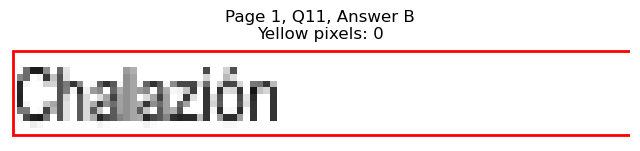

Page 1, Q11 - C: Detected box: x0=334.6, y0=695.4, x1=375.8, y1=708.0
Page 1, Q11, C: Yellow pixels: 92
Page 1, Q11, C: Total non-white pixels: 412
Page 1, Q11, C: Yellow percentage: 22.3%


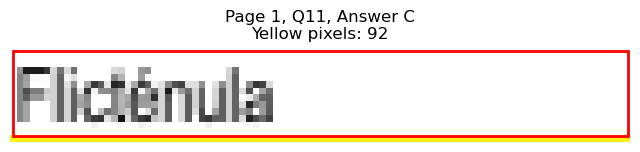

Page 1, Q11 - D: Detected box: x0=334.6, y0=708.0, x1=398.8, y1=720.6
Page 1, Q11, D: Yellow pixels: 1248
Page 1, Q11, D: Total non-white pixels: 1610
Page 1, Q11, D: Yellow percentage: 77.5%


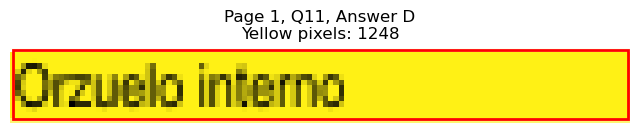


Page 1, Q11 - Selected Answer: D (based on yellow pixel count)





Page 2: Found 11 questions
Page 2, Q1 - A: Detected box: x0=75.4, y0=102.0, x1=141.6, y1=114.7
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 462
Page 2, Q1, A: Yellow percentage: 0.0%


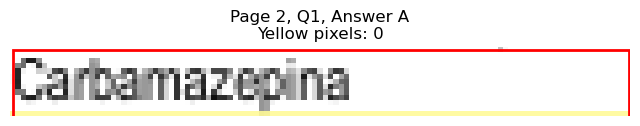

Page 2, Q1 - B: Detected box: x0=75.4, y0=114.6, x1=137.1, y1=127.3
Page 2, Q1, B: Yellow pixels: 1105
Page 2, Q1, B: Total non-white pixels: 1582
Page 2, Q1, B: Yellow percentage: 69.8%


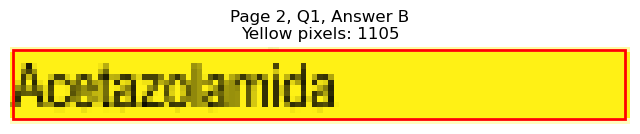

Page 2, Q1 - C: Detected box: x0=334.6, y0=102.0, x1=406.9, y1=114.7
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 384
Page 2, Q1, C: Yellow percentage: 0.0%


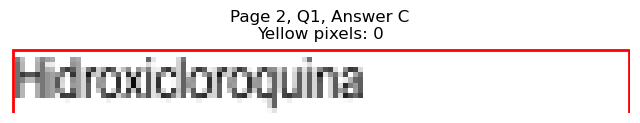

Page 2, Q1 - D: Detected box: x0=334.6, y0=114.6, x1=395.8, y1=127.3
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 319
Page 2, Q1, D: Yellow percentage: 0.0%


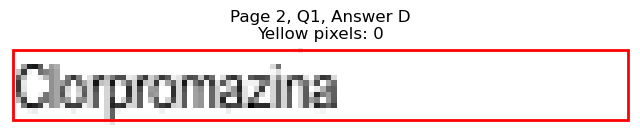


Page 2, Q1 - Selected Answer: B (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=75.4, y0=152.5, x1=175.7, y1=165.2
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 485
Page 2, Q2, A: Yellow percentage: 0.0%


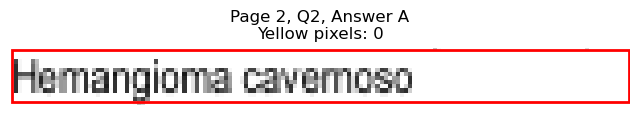

Page 2, Q2 - B: Detected box: x0=75.4, y0=165.1, x1=139.1, y1=177.8
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 341
Page 2, Q2, B: Yellow percentage: 0.0%


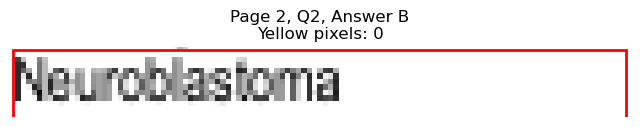

Page 2, Q2 - C: Detected box: x0=334.6, y0=152.5, x1=419.8, y1=165.2
Page 2, Q2, C: Yellow pixels: 1440
Page 2, Q2, C: Total non-white pixels: 1904
Page 2, Q2, C: Yellow percentage: 75.6%


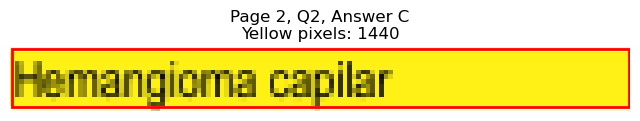

Page 2, Q2 - D: Detected box: x0=334.6, y0=165.1, x1=369.2, y1=177.8
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 256
Page 2, Q2, D: Yellow percentage: 0.0%


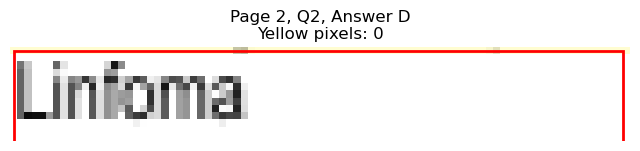


Page 2, Q2 - Selected Answer: C (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=75.4, y0=228.3, x1=142.1, y1=240.9
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 358
Page 2, Q3, A: Yellow percentage: 0.0%


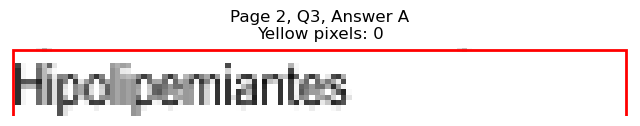

Page 2, Q3 - B: Detected box: x0=75.4, y0=240.9, x1=123.5, y1=253.5
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 222
Page 2, Q3, B: Yellow percentage: 0.0%


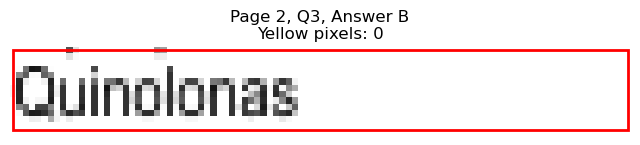

Page 2, Q3 - C: Detected box: x0=334.6, y0=228.3, x1=393.3, y1=240.9
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 425
Page 2, Q3, C: Yellow percentage: 0.0%


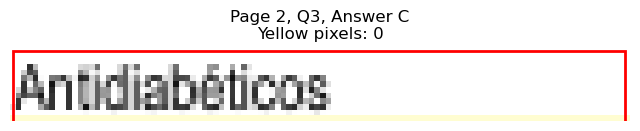

Page 2, Q3 - D: Detected box: x0=334.6, y0=240.9, x1=402.8, y1=253.5
Page 2, Q3, D: Yellow pixels: 1257
Page 2, Q3, D: Total non-white pixels: 1666
Page 2, Q3, D: Yellow percentage: 75.5%


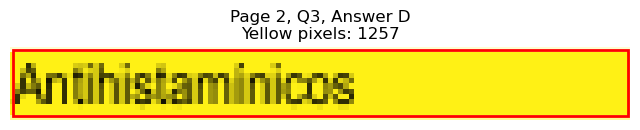


Page 2, Q3 - Selected Answer: D (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=75.4, y0=291.4, x1=128.5, y1=304.1
Page 2, Q4, A: Yellow pixels: 104
Page 2, Q4, A: Total non-white pixels: 353
Page 2, Q4, A: Yellow percentage: 29.5%


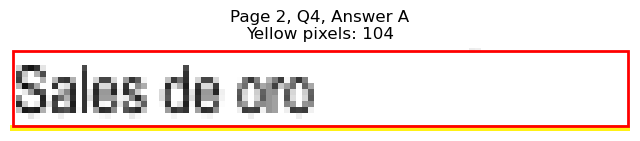

Page 2, Q4 - B: Detected box: x0=75.4, y0=304.0, x1=129.0, y1=316.7
Page 2, Q4, B: Yellow pixels: 1157
Page 2, Q4, B: Total non-white pixels: 1365
Page 2, Q4, B: Yellow percentage: 84.8%


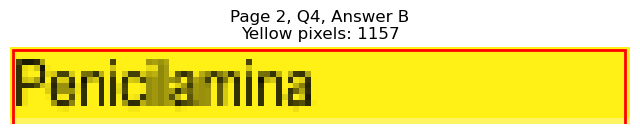

Page 2, Q4 - C: Detected box: x0=334.6, y0=102.0, x1=406.9, y1=114.7
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 384
Page 2, Q4, C: Yellow percentage: 0.0%


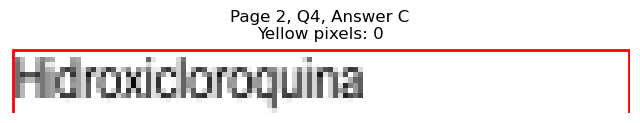

Page 2, Q4 - D: Detected box: x0=334.6, y0=304.0, x1=384.8, y1=316.7
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 274
Page 2, Q4, D: Yellow percentage: 0.0%


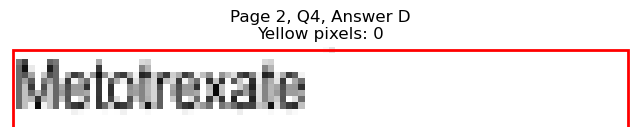


Page 2, Q4 - Selected Answer: B (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=75.4, y0=341.9, x1=128.1, y1=354.6
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 251
Page 2, Q5, A: Yellow percentage: 0.0%


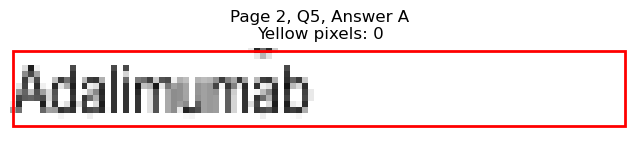

Page 2, Q5 - B: Detected box: x0=75.4, y0=354.5, x1=130.6, y1=367.2
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 267
Page 2, Q5, B: Yellow percentage: 0.0%


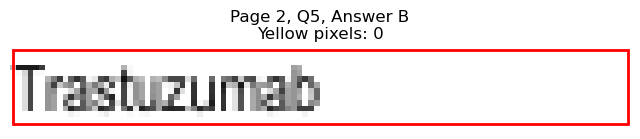

Page 2, Q5 - C: Detected box: x0=334.6, y0=341.9, x1=377.2, y1=354.6
Page 2, Q5, C: Yellow pixels: 1041
Page 2, Q5, C: Total non-white pixels: 1316
Page 2, Q5, C: Yellow percentage: 79.1%


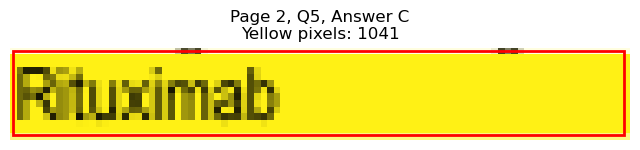

Page 2, Q5 - D: Detected box: x0=334.6, y0=354.5, x1=391.3, y1=367.2
Page 2, Q5, D: Yellow pixels: 108
Page 2, Q5, D: Total non-white pixels: 401
Page 2, Q5, D: Yellow percentage: 26.9%


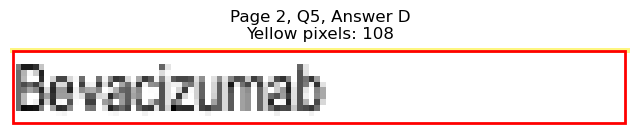


Page 2, Q5 - Selected Answer: C (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=75.4, y0=417.6, x1=182.7, y1=430.3
Page 2, Q6, A: Yellow pixels: 158
Page 2, Q6, A: Total non-white pixels: 697
Page 2, Q6, A: Yellow percentage: 22.7%


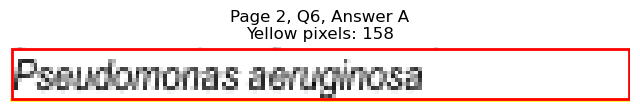

Page 2, Q6 - B: Detected box: x0=75.4, y0=430.2, x1=157.1, y1=442.9
Page 2, Q6, B: Yellow pixels: 1418
Page 2, Q6, B: Total non-white pixels: 1729
Page 2, Q6, B: Yellow percentage: 82.0%


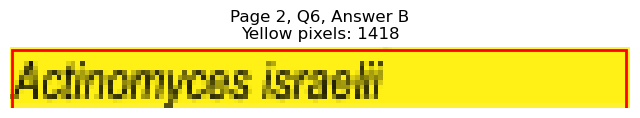

Page 2, Q6 - C: Detected box: x0=334.6, y0=417.6, x1=430.4, y1=430.3
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 474
Page 2, Q6, C: Yellow percentage: 0.0%


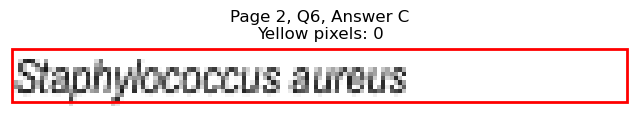

Page 2, Q6 - D: Detected box: x0=334.6, y0=430.2, x1=435.4, y1=442.9
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 530
Page 2, Q6, D: Yellow percentage: 0.0%


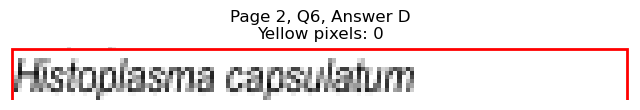


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=75.4, y0=468.1, x1=260.9, y1=480.7
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 910
Page 2, Q7, A: Yellow percentage: 0.0%


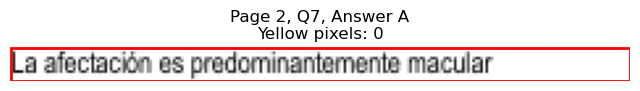

Page 2, Q7 - B: Detected box: x0=75.4, y0=480.8, x1=258.0, y1=493.4
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 918
Page 2, Q7, B: Yellow percentage: 0.0%


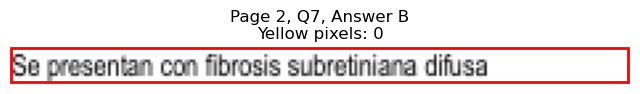

Page 2, Q7 - C: Detected box: x0=75.9, y0=493.4, x1=297.0, y1=506.0
Page 2, Q7, C: Yellow pixels: 273
Page 2, Q7, C: Total non-white pixels: 1608
Page 2, Q7, C: Yellow percentage: 17.0%


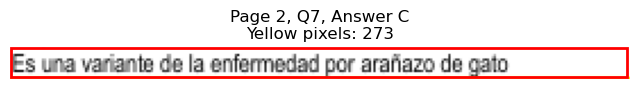

Page 2, Q7 - D: Detected box: x0=75.9, y0=506.0, x1=290.6, y1=518.6
Page 2, Q7, D: Yellow pixels: 2615
Page 2, Q7, D: Total non-white pixels: 3724
Page 2, Q7, D: Yellow percentage: 70.2%


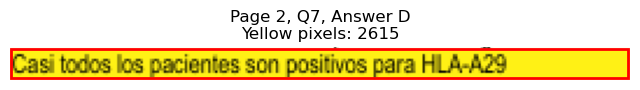


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=75.4, y0=543.8, x1=245.4, y1=556.4
Page 2, Q8, A: Yellow pixels: 2000
Page 2, Q8, A: Total non-white pixels: 2898
Page 2, Q8, A: Yellow percentage: 69.0%


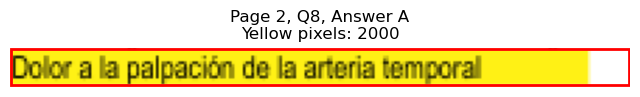

Page 2, Q8 - B: Detected box: x0=75.4, y0=556.5, x1=168.6, y1=569.2
Page 2, Q8, B: Yellow pixels: 144
Page 2, Q8, B: Total non-white pixels: 609
Page 2, Q8, B: Yellow percentage: 23.6%


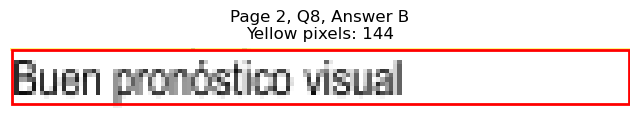

Page 2, Q8 - C: Detected box: x0=334.6, y0=543.8, x1=514.8, y1=556.4
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 936
Page 2, Q8, C: Yellow percentage: 0.0%


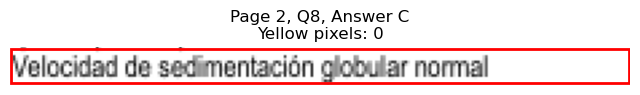

Page 2, Q8 - D: Detected box: x0=334.6, y0=556.5, x1=434.5, y1=569.2
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 543
Page 2, Q8, D: Yellow percentage: 0.0%


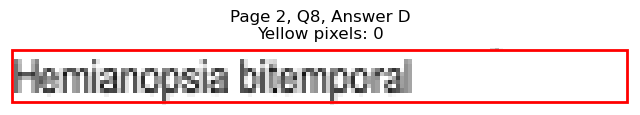


Page 2, Q8 - Selected Answer: A (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=75.4, y0=594.3, x1=348.2, y1=607.0
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 1319
Page 2, Q9, A: Yellow percentage: 0.0%


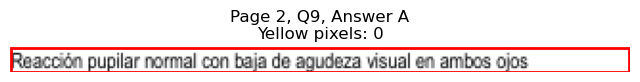

Page 2, Q9 - B: Detected box: x0=75.4, y0=606.9, x1=266.9, y1=619.6
Page 2, Q9, B: Yellow pixels: 0
Page 2, Q9, B: Total non-white pixels: 1003
Page 2, Q9, B: Yellow percentage: 0.0%


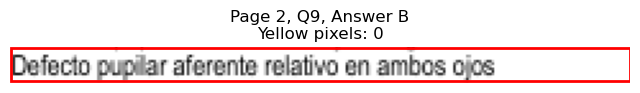

Page 2, Q9 - C: Detected box: x0=75.9, y0=619.6, x1=283.0, y1=632.3
Page 2, Q9, C: Yellow pixels: 259
Page 2, Q9, C: Total non-white pixels: 1273
Page 2, Q9, C: Yellow percentage: 20.3%


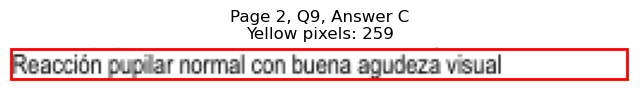

Page 2, Q9 - D: Detected box: x0=75.9, y0=632.2, x1=436.3, y1=644.9
Page 2, Q9, D: Yellow pixels: 4016
Page 2, Q9, D: Total non-white pixels: 5356
Page 2, Q9, D: Yellow percentage: 75.0%


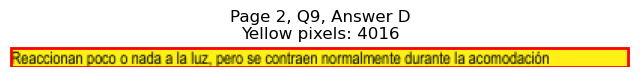


Page 2, Q9 - Selected Answer: D (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=75.4, y0=670.1, x1=223.4, y1=682.7
Page 2, Q10, A: Yellow pixels: 2051
Page 2, Q10, A: Total non-white pixels: 2587
Page 2, Q10, A: Yellow percentage: 79.3%


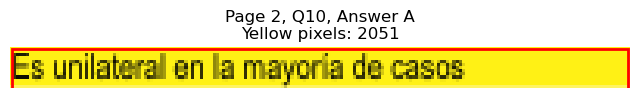

Page 2, Q10 - B: Detected box: x0=75.4, y0=682.7, x1=244.0, y1=695.3
Page 2, Q10, B: Yellow pixels: 205
Page 2, Q10, B: Total non-white pixels: 1018
Page 2, Q10, B: Yellow percentage: 20.1%


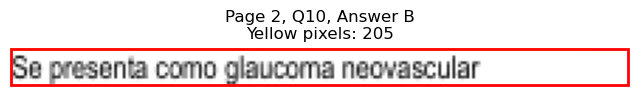

Page 2, Q10 - C: Detected box: x0=334.6, y0=670.1, x1=493.1, y1=682.7
Page 2, Q10, C: Yellow pixels: 0
Page 2, Q10, C: Total non-white pixels: 778
Page 2, Q10, C: Yellow percentage: 0.0%


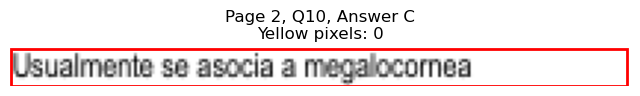

Page 2, Q10 - D: Detected box: x0=334.6, y0=682.7, x1=528.8, y1=695.3
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 956
Page 2, Q10, D: Yellow percentage: 0.0%


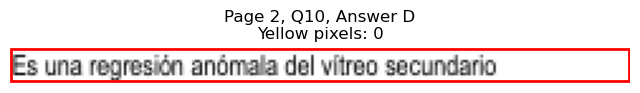


Page 2, Q10 - Selected Answer: A (based on yellow pixel count)




Page 2, Q11 - A: Detected box: x0=75.4, y0=720.6, x1=187.7, y1=733.2
Page 2, Q11, A: Yellow pixels: 163
Page 2, Q11, A: Total non-white pixels: 740
Page 2, Q11, A: Yellow percentage: 22.0%


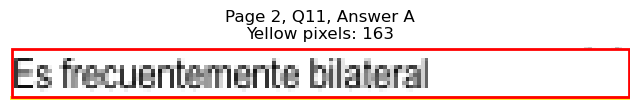

Page 2, Q11 - B: Detected box: x0=75.4, y0=733.2, x1=237.4, y1=745.8
Page 2, Q11, B: Yellow pixels: 2069
Page 2, Q11, B: Total non-white pixels: 2691
Page 2, Q11, B: Yellow percentage: 76.9%


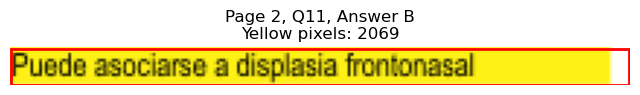

Page 2, Q11 - C: Detected box: x0=334.6, y0=720.6, x1=540.8, y1=733.2
Page 2, Q11, C: Yellow pixels: 0
Page 2, Q11, C: Total non-white pixels: 1038
Page 2, Q11, C: Yellow percentage: 0.0%


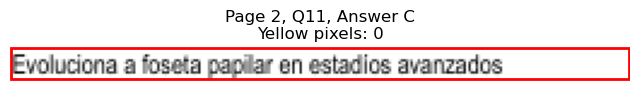

Page 2, Q11 - D: Detected box: x0=334.6, y0=733.2, x1=520.2, y1=745.8
Page 2, Q11, D: Yellow pixels: 0
Page 2, Q11, D: Total non-white pixels: 925
Page 2, Q11, D: Yellow percentage: 0.0%


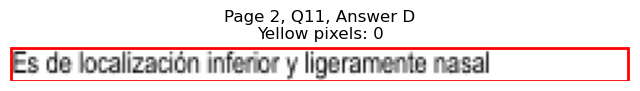


Page 2, Q11 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 10 questions
Page 3, Q1 - A: Detected box: x0=75.4, y0=89.4, x1=187.2, y1=102.1
Page 3, Q1, A: Yellow pixels: 163
Page 3, Q1, A: Total non-white pixels: 732
Page 3, Q1, A: Yellow percentage: 22.3%


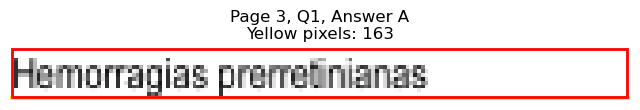

Page 3, Q1 - B: Detected box: x0=75.4, y0=102.0, x1=227.3, y1=114.7
Page 3, Q1, B: Yellow pixels: 1993
Page 3, Q1, B: Total non-white pixels: 2639
Page 3, Q1, B: Yellow percentage: 75.5%


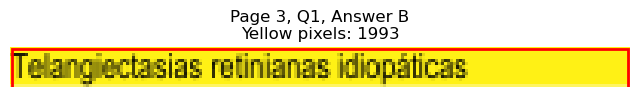

Page 3, Q1 - C: Detected box: x0=334.6, y0=89.4, x1=502.7, y1=102.1
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 821
Page 3, Q1, C: Yellow percentage: 0.0%


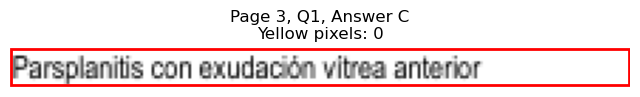

Page 3, Q1 - D: Detected box: x0=334.6, y0=102.0, x1=498.6, y1=114.7
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 839
Page 3, Q1, D: Yellow percentage: 0.0%


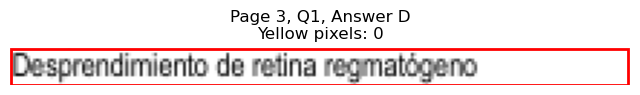


Page 3, Q1 - Selected Answer: B (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=75.4, y0=152.5, x1=95.9, y1=165.2
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 84
Page 3, Q2, A: Yellow percentage: 0.0%


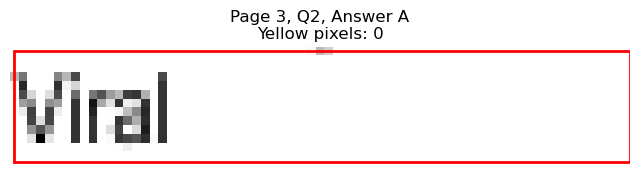

Page 3, Q2 - B: Detected box: x0=75.4, y0=165.1, x1=121.0, y1=177.8
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 223
Page 3, Q2, B: Yellow percentage: 0.0%


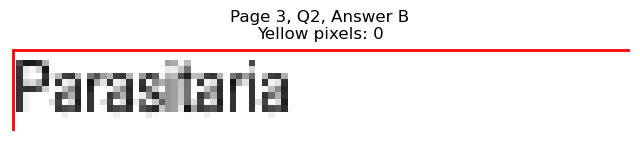

Page 3, Q2 - C: Detected box: x0=334.6, y0=152.5, x1=380.2, y1=165.2
Page 3, Q2, C: Yellow pixels: 97
Page 3, Q2, C: Total non-white pixels: 337
Page 3, Q2, C: Yellow percentage: 28.8%


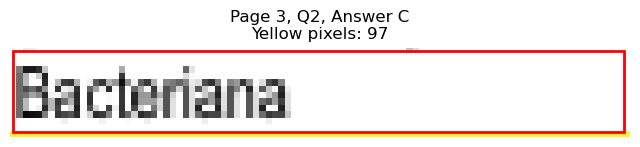

Page 3, Q2 - D: Detected box: x0=334.6, y0=165.1, x1=370.3, y1=177.8
Page 3, Q2, D: Yellow pixels: 971
Page 3, Q2, D: Total non-white pixels: 1131
Page 3, Q2, D: Yellow percentage: 85.9%


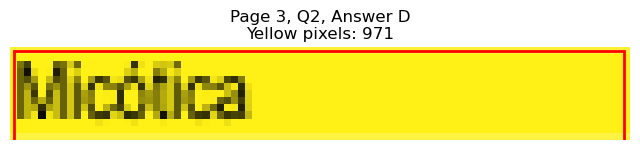


Page 3, Q2 - Selected Answer: D (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=75.4, y0=202.9, x1=423.5, y1=215.6
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 1771
Page 3, Q3, A: Yellow percentage: 0.0%


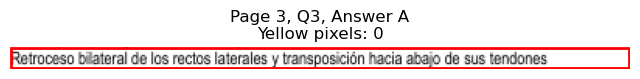

Page 3, Q3 - B: Detected box: x0=75.4, y0=215.7, x1=419.5, y1=228.3
Page 3, Q3, B: Yellow pixels: 3419
Page 3, Q3, B: Total non-white pixels: 5530
Page 3, Q3, B: Yellow percentage: 61.8%


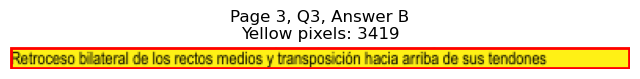

Page 3, Q3 - C: Detected box: x0=75.9, y0=228.3, x1=425.9, y1=240.9
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 2161
Page 3, Q3, C: Yellow percentage: 0.0%


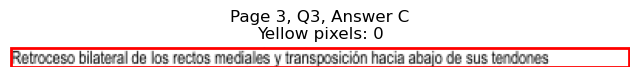

Page 3, Q3 - D: Detected box: x0=75.9, y0=240.9, x1=425.0, y1=253.5
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 1733
Page 3, Q3, D: Yellow percentage: 0.0%


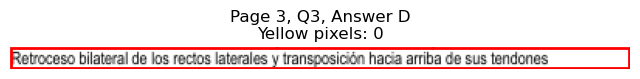


Page 3, Q3 - Selected Answer: B (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=75.4, y0=316.6, x1=153.1, y1=329.3
Page 3, Q4, A: Yellow pixels: 129
Page 3, Q4, A: Total non-white pixels: 498
Page 3, Q4, A: Yellow percentage: 25.9%


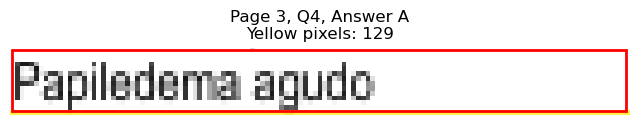

Page 3, Q4 - B: Detected box: x0=75.4, y0=329.2, x1=181.2, y1=341.9
Page 3, Q4, B: Yellow pixels: 1612
Page 3, Q4, B: Total non-white pixels: 2041
Page 3, Q4, B: Yellow percentage: 79.0%


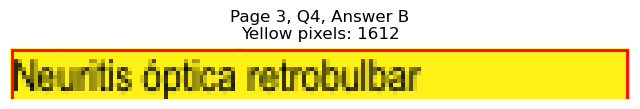

Page 3, Q4 - C: Detected box: x0=334.6, y0=316.6, x1=489.2, y1=329.3
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 799
Page 3, Q4, C: Yellow percentage: 0.0%


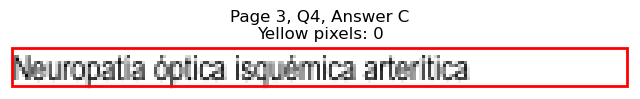

Page 3, Q4 - D: Detected box: x0=334.6, y0=329.2, x1=501.7, y1=341.9
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 838
Page 3, Q4, D: Yellow percentage: 0.0%


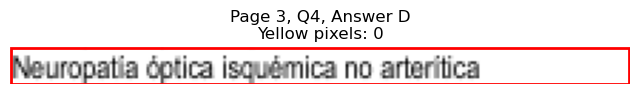


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=75.4, y0=367.1, x1=322.2, y1=379.8
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 1503
Page 3, Q5, A: Yellow percentage: 0.0%


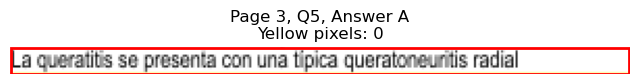

Page 3, Q5 - B: Detected box: x0=75.4, y0=379.7, x1=343.1, y1=392.4
Page 3, Q5, B: Yellow pixels: 2831
Page 3, Q5, B: Total non-white pixels: 4466
Page 3, Q5, B: Yellow percentage: 63.4%


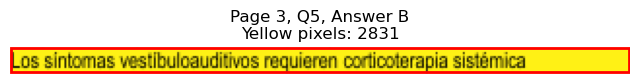

Page 3, Q5 - C: Detected box: x0=75.9, y0=392.3, x1=300.6, y1=405.0
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 1318
Page 3, Q5, C: Yellow percentage: 0.0%


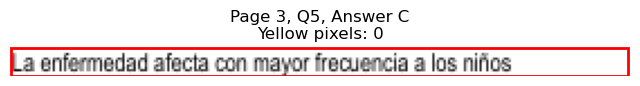

Page 3, Q5 - D: Detected box: x0=75.9, y0=404.9, x1=372.8, y1=417.6
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 1492
Page 3, Q5, D: Yellow percentage: 0.0%


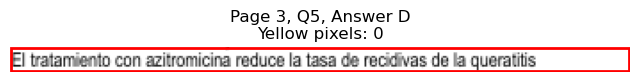


Page 3, Q5 - Selected Answer: B (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=75.4, y0=442.8, x1=194.2, y1=455.5
Page 3, Q6, A: Yellow pixels: 1715
Page 3, Q6, A: Total non-white pixels: 2380
Page 3, Q6, A: Yellow percentage: 72.1%


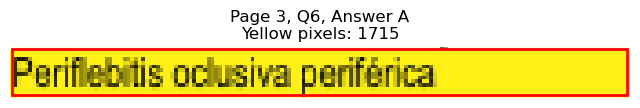

Page 3, Q6 - B: Detected box: x0=75.4, y0=455.5, x1=230.4, y1=468.1
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 766
Page 3, Q6, B: Yellow percentage: 0.0%


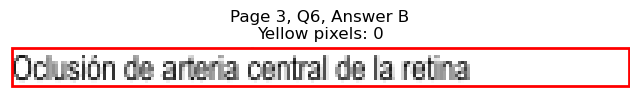

Page 3, Q6 - C: Detected box: x0=334.6, y0=442.8, x1=461.5, y1=455.5
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 656
Page 3, Q6, C: Yellow percentage: 0.0%


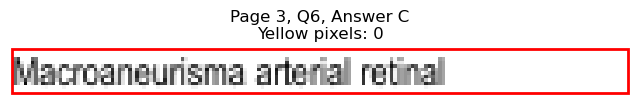

Page 3, Q6 - D: Detected box: x0=334.6, y0=455.5, x1=432.4, y1=468.1
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 489
Page 3, Q6, D: Yellow percentage: 0.0%


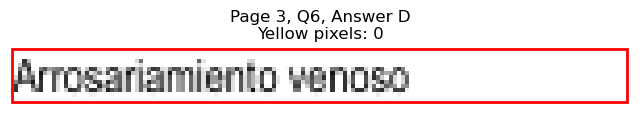


Page 3, Q6 - Selected Answer: A (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=75.4, y0=531.2, x1=127.0, y1=543.8
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 276
Page 3, Q7, A: Yellow percentage: 0.0%


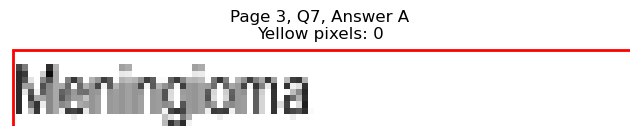

Page 3, Q7 - B: Detected box: x0=75.4, y0=543.8, x1=122.5, y1=556.4
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 250
Page 3, Q7, B: Yellow percentage: 0.0%


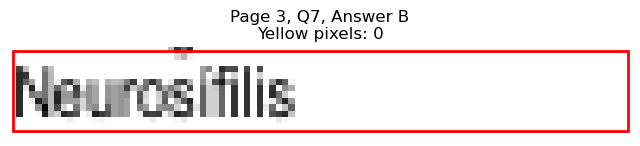

Page 3, Q7 - C: Detected box: x0=334.6, y0=531.2, x1=369.7, y1=543.8
Page 3, Q7, C: Yellow pixels: 997
Page 3, Q7, C: Total non-white pixels: 1118
Page 3, Q7, C: Yellow percentage: 89.2%


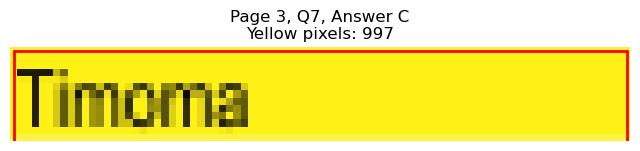

Page 3, Q7 - D: Detected box: x0=334.6, y0=543.8, x1=382.3, y1=556.4
Page 3, Q7, D: Yellow pixels: 99
Page 3, Q7, D: Total non-white pixels: 366
Page 3, Q7, D: Yellow percentage: 27.0%


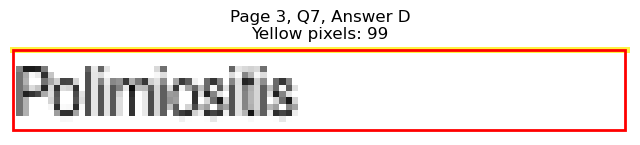


Page 3, Q7 - Selected Answer: C (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=75.4, y0=606.9, x1=187.2, y1=619.6
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 562
Page 3, Q8, A: Yellow percentage: 0.0%


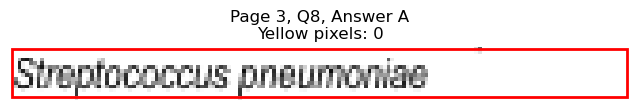

Page 3, Q8 - B: Detected box: x0=75.4, y0=619.6, x1=171.1, y1=632.3
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 482
Page 3, Q8, B: Yellow percentage: 0.0%


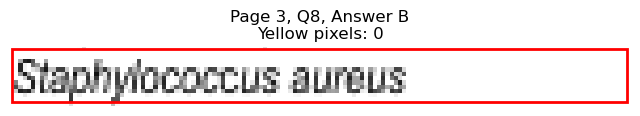

Page 3, Q8 - C: Detected box: x0=334.6, y0=606.9, x1=427.9, y1=619.6
Page 3, Q8, C: Yellow pixels: 1514
Page 3, Q8, C: Total non-white pixels: 2016
Page 3, Q8, C: Yellow percentage: 75.1%


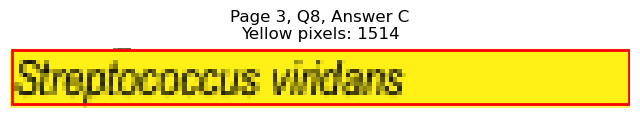

Page 3, Q8 - D: Detected box: x0=334.6, y0=619.6, x1=428.5, y1=632.3
Page 3, Q8, D: Yellow pixels: 145
Page 3, Q8, D: Total non-white pixels: 630
Page 3, Q8, D: Yellow percentage: 23.0%


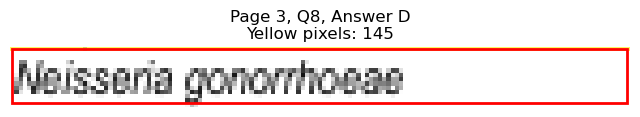


Page 3, Q8 - Selected Answer: C (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=75.4, y0=657.5, x1=133.1, y1=670.1
Page 3, Q9, A: Yellow pixels: 1196
Page 3, Q9, A: Total non-white pixels: 1526
Page 3, Q9, A: Yellow percentage: 78.4%


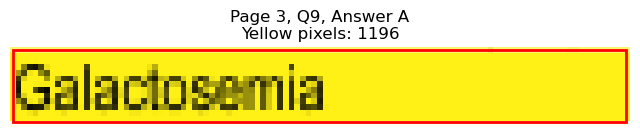

Page 3, Q9 - B: Detected box: x0=75.4, y0=670.1, x1=111.5, y1=682.7
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 282
Page 3, Q9, B: Yellow percentage: 0.0%


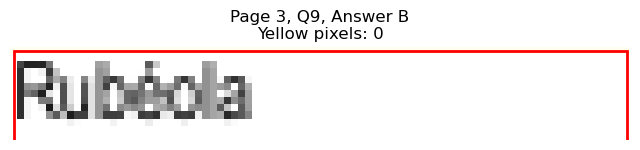

Page 3, Q9 - C: Detected box: x0=334.6, y0=657.5, x1=369.8, y1=670.1
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 177
Page 3, Q9, C: Yellow percentage: 0.0%


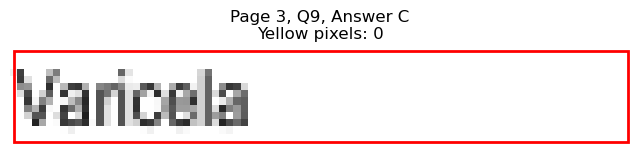

Page 3, Q9 - D: Detected box: x0=334.6, y0=670.1, x1=384.8, y1=682.7
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 214
Page 3, Q9, D: Yellow percentage: 0.0%


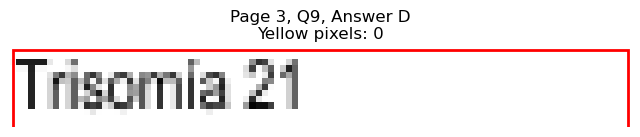


Page 3, Q9 - Selected Answer: A (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=75.4, y0=708.0, x1=119.1, y1=720.6
Page 3, Q10, A: Yellow pixels: 0
Page 3, Q10, A: Total non-white pixels: 201
Page 3, Q10, A: Yellow percentage: 0.0%


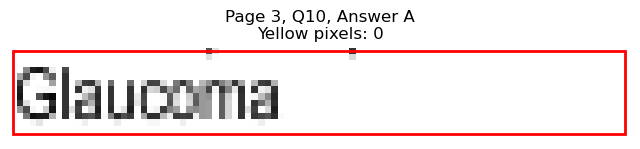

Page 3, Q10 - B: Detected box: x0=75.4, y0=720.6, x1=112.5, y1=733.2
Page 3, Q10, B: Yellow pixels: 0
Page 3, Q10, B: Total non-white pixels: 187
Page 3, Q10, B: Yellow percentage: 0.0%


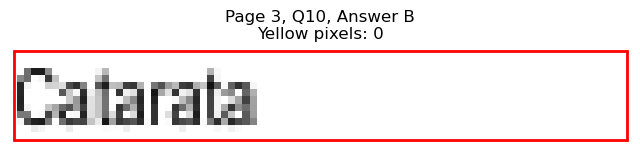

Page 3, Q10 - C: Detected box: x0=334.6, y0=708.0, x1=372.8, y1=720.6
Page 3, Q10, C: Yellow pixels: 1026
Page 3, Q10, C: Total non-white pixels: 1246
Page 3, Q10, C: Yellow percentage: 82.3%


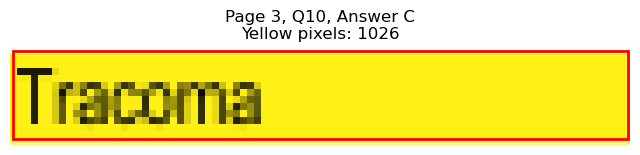

Page 3, Q10 - D: Detected box: x0=334.6, y0=720.6, x1=386.3, y1=733.2
Page 3, Q10, D: Yellow pixels: 103
Page 3, Q10, D: Total non-white pixels: 383
Page 3, Q10, D: Yellow percentage: 26.9%


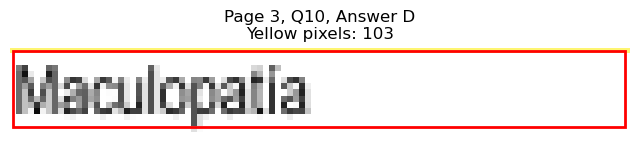


Page 3, Q10 - Selected Answer: C (based on yellow pixel count)





Page 4: Found 12 questions
Page 4, Q1 - A: Detected box: x0=75.4, y0=114.6, x1=116.5, y1=127.3
Page 4, Q1, A: Yellow pixels: 92
Page 4, Q1, A: Total non-white pixels: 306
Page 4, Q1, A: Yellow percentage: 30.1%


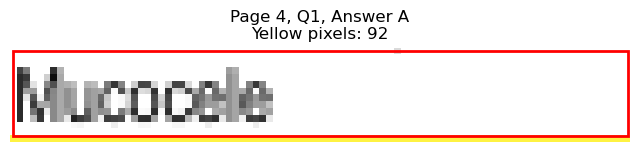

Page 4, Q1 - B: Detected box: x0=75.4, y0=127.2, x1=153.6, y1=139.9
Page 4, Q1, B: Yellow pixels: 1358
Page 4, Q1, B: Total non-white pixels: 1677
Page 4, Q1, B: Yellow percentage: 81.0%


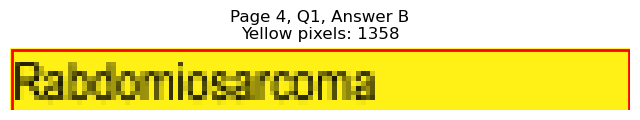

Page 4, Q1 - C: Detected box: x0=334.6, y0=114.6, x1=403.4, y1=127.3
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 382
Page 4, Q1, C: Yellow percentage: 0.0%


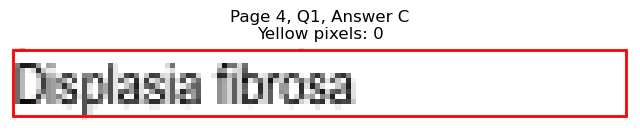

Page 4, Q1 - D: Detected box: x0=334.6, y0=127.2, x1=384.8, y1=139.9
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 284
Page 4, Q1, D: Yellow percentage: 0.0%


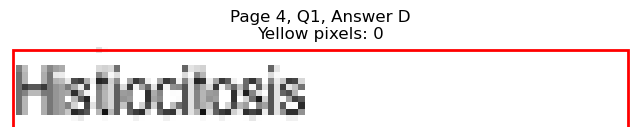


Page 4, Q1 - Selected Answer: B (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=75.4, y0=165.1, x1=165.6, y1=177.8
Page 4, Q2, A: Yellow pixels: 1476
Page 4, Q2, A: Total non-white pixels: 1833
Page 4, Q2, A: Yellow percentage: 80.5%


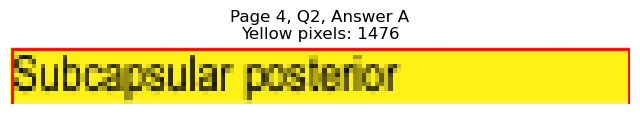

Page 4, Q2 - B: Detected box: x0=75.4, y0=177.7, x1=138.0, y1=190.4
Page 4, Q2, B: Yellow pixels: 114
Page 4, Q2, B: Total non-white pixels: 427
Page 4, Q2, B: Yellow percentage: 26.7%


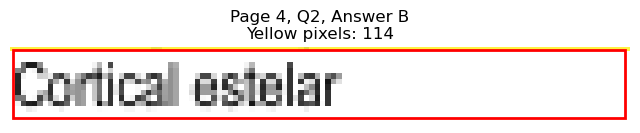

Page 4, Q2 - C: Detected box: x0=334.6, y0=165.1, x1=395.3, y1=177.8
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 314
Page 4, Q2, C: Yellow percentage: 0.0%


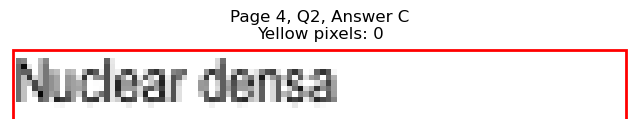

Page 4, Q2 - D: Detected box: x0=334.6, y0=177.7, x1=391.3, y1=190.4
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 280
Page 4, Q2, D: Yellow percentage: 0.0%


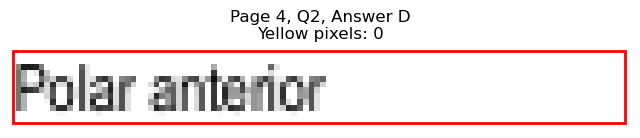


Page 4, Q2 - Selected Answer: A (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=75.4, y0=240.9, x1=137.1, y1=253.5
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 313
Page 4, Q3, A: Yellow percentage: 0.0%


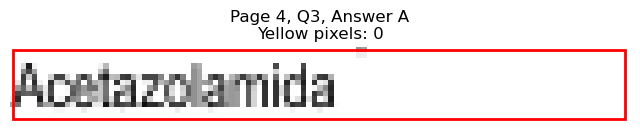

Page 4, Q3 - B: Detected box: x0=75.4, y0=253.5, x1=118.5, y1=266.1
Page 4, Q3, B: Yellow pixels: 0
Page 4, Q3, B: Total non-white pixels: 214
Page 4, Q3, B: Yellow percentage: 0.0%


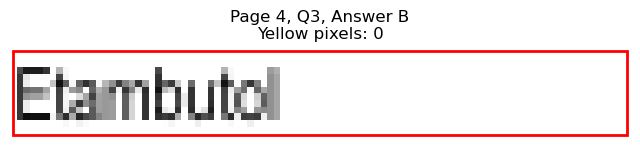

Page 4, Q3 - C: Detected box: x0=334.6, y0=240.9, x1=369.2, y1=253.5
Page 4, Q3, C: Yellow pixels: 86
Page 4, Q3, C: Total non-white pixels: 259
Page 4, Q3, C: Yellow percentage: 33.2%


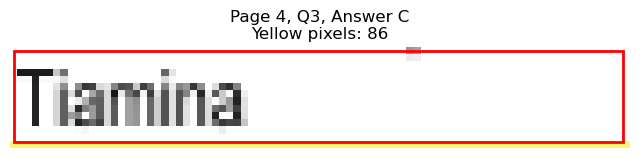

Page 4, Q3 - D: Detected box: x0=334.6, y0=253.5, x1=383.2, y1=266.1
Page 4, Q3, D: Yellow pixels: 1129
Page 4, Q3, D: Total non-white pixels: 1400
Page 4, Q3, D: Yellow percentage: 80.6%


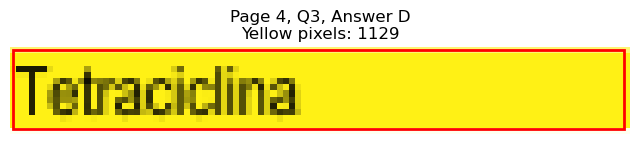


Page 4, Q3 - Selected Answer: D (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=75.4, y0=304.0, x1=86.4, y1=316.7
Page 4, Q4, A: Yellow pixels: 766
Page 4, Q4, A: Total non-white pixels: 806
Page 4, Q4, A: Yellow percentage: 95.0%


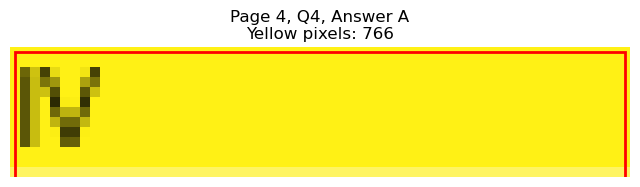

Page 4, Q4 - B: Detected box: x0=75.4, y0=316.6, x1=85.5, y1=329.3
Page 4, Q4, B: Yellow pixels: 61
Page 4, Q4, B: Total non-white pixels: 109
Page 4, Q4, B: Yellow percentage: 56.0%


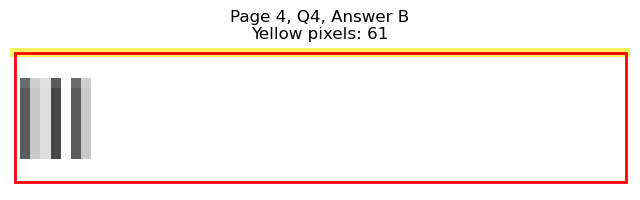

Page 4, Q4 - C: Detected box: x0=322.5, y0=304.0, x1=331.5, y1=316.7
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 60
Page 4, Q4, C: Yellow percentage: 0.0%


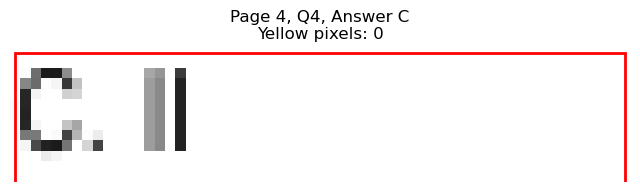

Page 4, Q4 - D: Detected box: x0=322.5, y0=316.6, x1=331.5, y1=329.3
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 56
Page 4, Q4, D: Yellow percentage: 0.0%


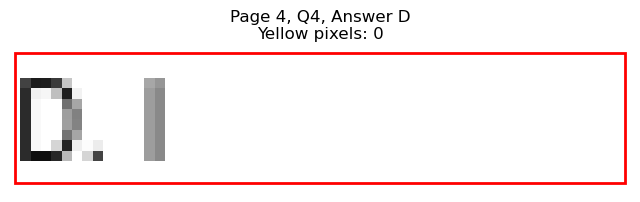


Page 4, Q4 - Selected Answer: A (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=75.4, y0=367.1, x1=156.1, y1=379.8
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 544
Page 4, Q5, A: Yellow percentage: 0.0%


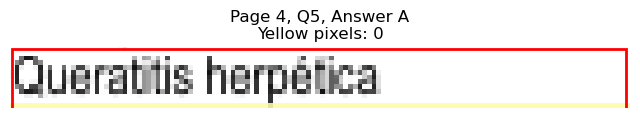

Page 4, Q5 - B: Detected box: x0=75.4, y0=379.7, x1=147.1, y1=392.4
Page 4, Q5, B: Yellow pixels: 1196
Page 4, Q5, B: Total non-white pixels: 1722
Page 4, Q5, B: Yellow percentage: 69.5%


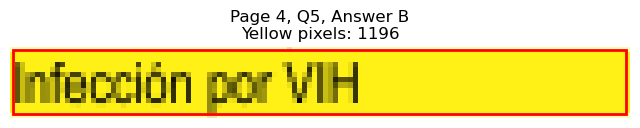

Page 4, Q5 - C: Detected box: x0=334.6, y0=367.1, x1=429.4, y1=379.8
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 482
Page 4, Q5, C: Yellow percentage: 0.0%


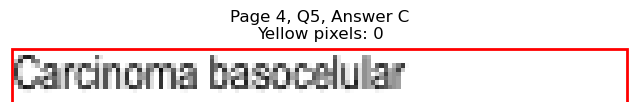

Page 4, Q5 - D: Detected box: x0=334.6, y0=379.7, x1=416.3, y1=392.4
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 424
Page 4, Q5, D: Yellow percentage: 0.0%


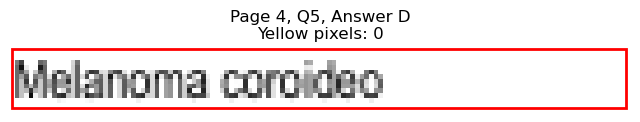


Page 4, Q5 - Selected Answer: B (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=75.4, y0=417.6, x1=128.1, y1=430.3
Page 4, Q6, A: Yellow pixels: 104
Page 4, Q6, A: Total non-white pixels: 353
Page 4, Q6, A: Yellow percentage: 29.5%


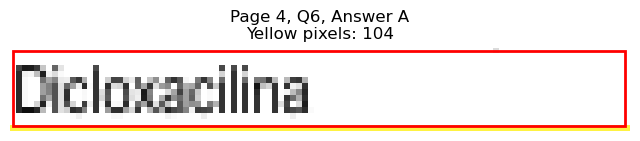

Page 4, Q6 - B: Detected box: x0=75.4, y0=430.2, x1=125.5, y1=442.9
Page 4, Q6, B: Yellow pixels: 1112
Page 4, Q6, B: Total non-white pixels: 1313
Page 4, Q6, B: Yellow percentage: 84.7%


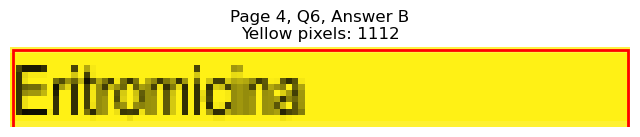

Page 4, Q6 - C: Detected box: x0=334.6, y0=417.6, x1=389.8, y1=430.3
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 289
Page 4, Q6, C: Yellow percentage: 0.0%


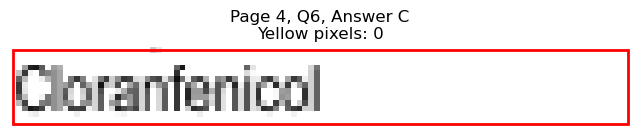

Page 4, Q6 - D: Detected box: x0=334.6, y0=430.2, x1=394.3, y1=442.9
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 307
Page 4, Q6, D: Yellow percentage: 0.0%


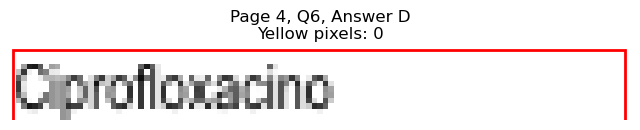


Page 4, Q6 - Selected Answer: B (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=75.4, y0=480.8, x1=188.2, y1=493.4
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 581
Page 4, Q7, A: Yellow percentage: 0.0%


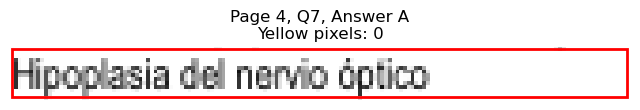

Page 4, Q7 - B: Detected box: x0=75.4, y0=493.4, x1=223.8, y1=506.0
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 764
Page 4, Q7, B: Yellow percentage: 0.0%


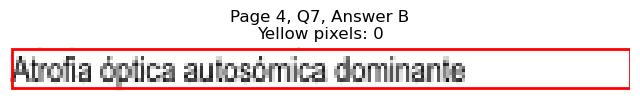

Page 4, Q7 - C: Detected box: x0=334.6, y0=480.8, x1=451.5, y1=493.4
Page 4, Q7, C: Yellow pixels: 168
Page 4, Q7, C: Total non-white pixels: 771
Page 4, Q7, C: Yellow percentage: 21.8%


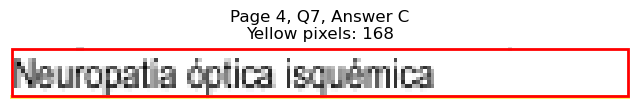

Page 4, Q7 - D: Detected box: x0=334.6, y0=493.4, x1=446.5, y1=506.0
Page 4, Q7, D: Yellow pixels: 1659
Page 4, Q7, D: Total non-white pixels: 2122
Page 4, Q7, D: Yellow percentage: 78.2%


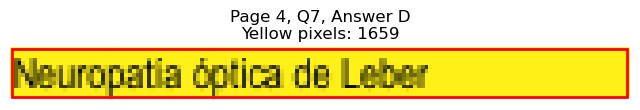


Page 4, Q7 - Selected Answer: D (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=75.4, y0=543.8, x1=153.6, y1=556.4
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 408
Page 4, Q8, A: Yellow percentage: 0.0%


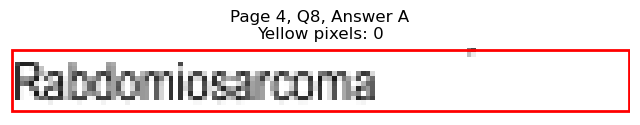

Page 4, Q8 - B: Detected box: x0=75.4, y0=556.5, x1=175.7, y1=569.2
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 482
Page 4, Q8, B: Yellow percentage: 0.0%


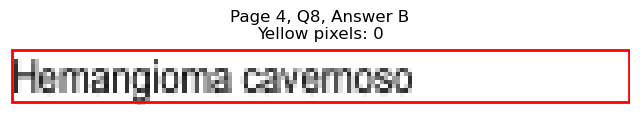

Page 4, Q8 - C: Detected box: x0=334.6, y0=543.8, x1=440.5, y1=556.4
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 523
Page 4, Q8, C: Yellow percentage: 0.0%


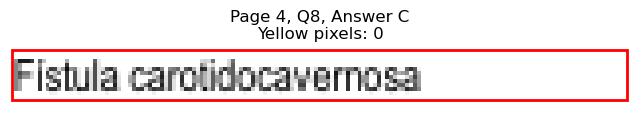

Page 4, Q8 - D: Detected box: x0=334.6, y0=556.5, x1=392.2, y1=569.2
Page 4, Q8, D: Yellow pixels: 1181
Page 4, Q8, D: Total non-white pixels: 1526
Page 4, Q8, D: Yellow percentage: 77.4%


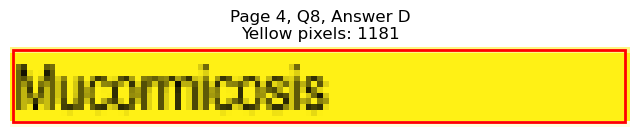


Page 4, Q8 - Selected Answer: D (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=75.4, y0=594.3, x1=226.8, y1=607.0
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 706
Page 4, Q9, A: Yellow percentage: 0.0%


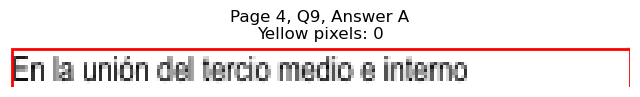

Page 4, Q9 - B: Detected box: x0=75.4, y0=606.9, x1=153.1, y1=619.6
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 358
Page 4, Q9, B: Yellow percentage: 0.0%


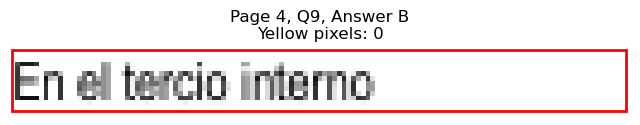

Page 4, Q9 - C: Detected box: x0=334.6, y0=594.3, x1=414.9, y1=607.0
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 486
Page 4, Q9, C: Yellow percentage: 0.0%


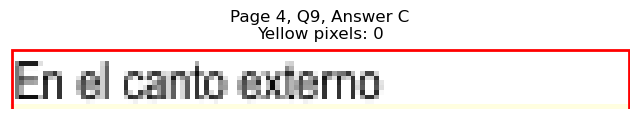

Page 4, Q9 - D: Detected box: x0=334.6, y0=606.9, x1=488.1, y1=619.6
Page 4, Q9, D: Yellow pixels: 2117
Page 4, Q9, D: Total non-white pixels: 2870
Page 4, Q9, D: Yellow percentage: 73.8%


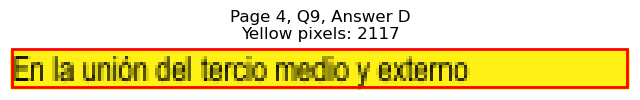


Page 4, Q9 - Selected Answer: D (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=75.4, y0=644.9, x1=126.5, y1=657.5
Page 4, Q10, A: Yellow pixels: 0
Page 4, Q10, A: Total non-white pixels: 240
Page 4, Q10, A: Yellow percentage: 0.0%


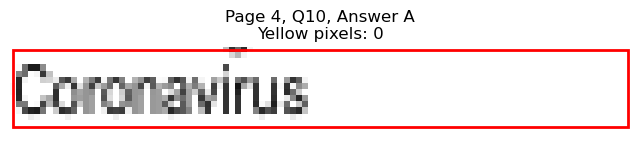

Page 4, Q10 - B: Detected box: x0=75.4, y0=657.5, x1=142.6, y1=670.1
Page 4, Q10, B: Yellow pixels: 0
Page 4, Q10, B: Total non-white pixels: 351
Page 4, Q10, B: Yellow percentage: 0.0%


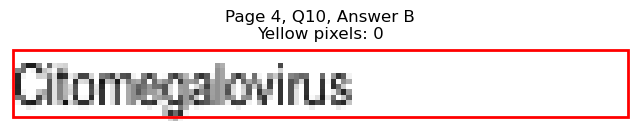

Page 4, Q10 - C: Detected box: x0=334.6, y0=644.9, x1=371.7, y1=657.5
Page 4, Q10, C: Yellow pixels: 88
Page 4, Q10, C: Total non-white pixels: 270
Page 4, Q10, C: Yellow percentage: 32.6%


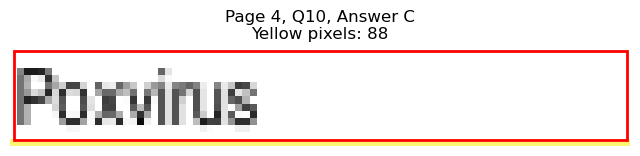

Page 4, Q10 - D: Detected box: x0=334.6, y0=657.5, x1=397.9, y1=670.1
Page 4, Q10, D: Yellow pixels: 1241
Page 4, Q10, D: Total non-white pixels: 1596
Page 4, Q10, D: Yellow percentage: 77.8%


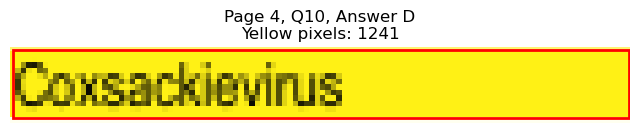


Page 4, Q10 - Selected Answer: D (based on yellow pixel count)




Page 4, Q11 - A: Detected box: x0=75.4, y0=695.4, x1=200.8, y1=708.0
Page 4, Q11, A: Yellow pixels: 0
Page 4, Q11, A: Total non-white pixels: 628
Page 4, Q11, A: Yellow percentage: 0.0%


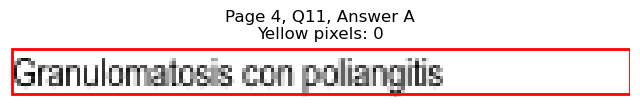

Page 4, Q11 - B: Detected box: x0=75.4, y0=708.0, x1=192.3, y1=720.6
Page 4, Q11, B: Yellow pixels: 0
Page 4, Q11, B: Total non-white pixels: 567
Page 4, Q11, B: Yellow percentage: 0.0%


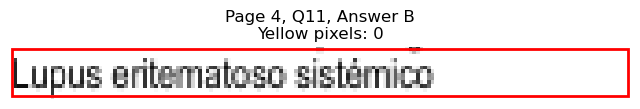

Page 4, Q11 - C: Detected box: x0=334.6, y0=695.4, x1=415.4, y1=708.0
Page 4, Q11, C: Yellow pixels: 1405
Page 4, Q11, C: Total non-white pixels: 1716
Page 4, Q11, C: Yellow percentage: 81.9%


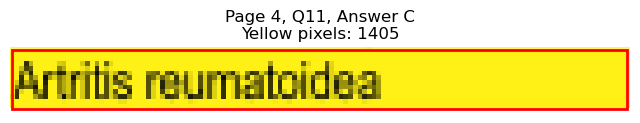

Page 4, Q11 - D: Detected box: x0=334.6, y0=708.0, x1=413.8, y1=720.6
Page 4, Q11, D: Yellow pixels: 130
Page 4, Q11, D: Total non-white pixels: 551
Page 4, Q11, D: Yellow percentage: 23.6%


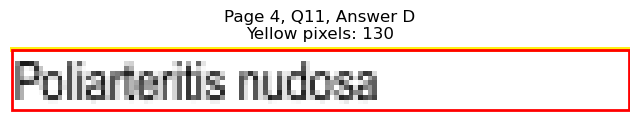


Page 4, Q11 - Selected Answer: C (based on yellow pixel count)




Page 4, Q12 - A: Detected box: x0=75.4, y0=745.8, x1=132.0, y1=758.4
Page 4, Q12, A: Yellow pixels: 1204
Page 4, Q12, A: Total non-white pixels: 1512
Page 4, Q12, A: Yellow percentage: 79.6%


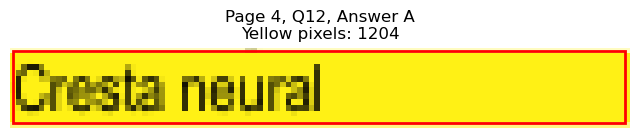

Page 4, Q12 - B: Detected box: x0=75.4, y0=758.5, x1=145.1, y1=771.2
Page 4, Q12, B: Yellow pixels: 121
Page 4, Q12, B: Total non-white pixels: 475
Page 4, Q12, B: Yellow percentage: 25.5%


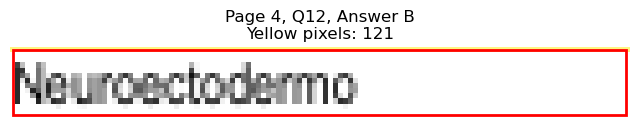

Page 4, Q12 - C: Detected box: x0=334.6, y0=745.8, x1=384.8, y1=758.4
Page 4, Q12, C: Yellow pixels: 0
Page 4, Q12, C: Total non-white pixels: 257
Page 4, Q12, C: Yellow percentage: 0.0%


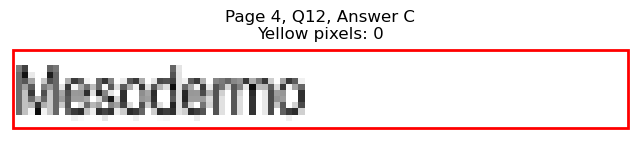

Page 4, Q12 - D: Detected box: x0=334.6, y0=758.5, x1=421.4, y1=771.2
Page 4, Q12, D: Yellow pixels: 0
Page 4, Q12, D: Total non-white pixels: 440
Page 4, Q12, D: Yellow percentage: 0.0%


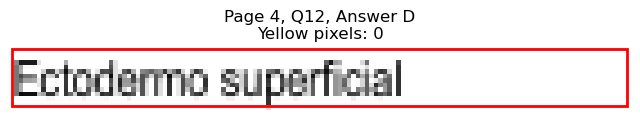


Page 4, Q12 - Selected Answer: A (based on yellow pixel count)





Page 5: Found 11 questions
Page 5, Q1 - A: Detected box: x0=75.4, y0=89.4, x1=125.5, y1=102.1
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 256
Page 5, Q1, A: Yellow percentage: 0.0%


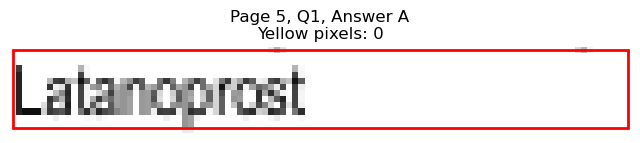

Page 5, Q1 - B: Detected box: x0=75.4, y0=102.0, x1=125.5, y1=114.7
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 259
Page 5, Q1, B: Yellow percentage: 0.0%


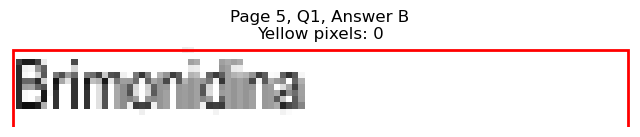

Page 5, Q1 - C: Detected box: x0=334.6, y0=89.4, x1=379.3, y1=102.1
Page 5, Q1, C: Yellow pixels: 96
Page 5, Q1, C: Total non-white pixels: 336
Page 5, Q1, C: Yellow percentage: 28.6%


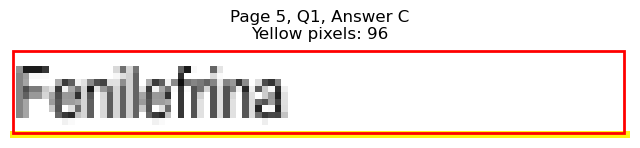

Page 5, Q1 - D: Detected box: x0=334.6, y0=102.0, x1=380.2, y1=114.7
Page 5, Q1, D: Yellow pixels: 1077
Page 5, Q1, D: Total non-white pixels: 1261
Page 5, Q1, D: Yellow percentage: 85.4%


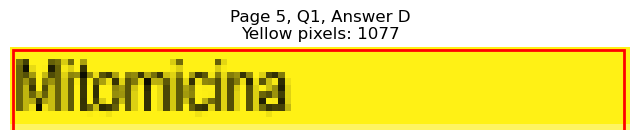


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=75.4, y0=139.9, x1=124.6, y1=152.6
Page 5, Q2, A: Yellow pixels: 100
Page 5, Q2, A: Total non-white pixels: 347
Page 5, Q2, A: Yellow percentage: 28.8%


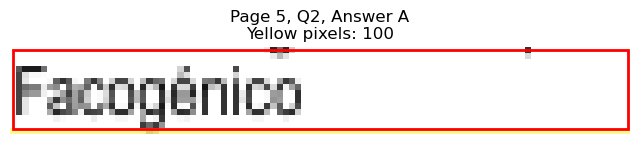

Page 5, Q2 - B: Detected box: x0=75.4, y0=152.5, x1=144.1, y1=165.2
Page 5, Q2, B: Yellow pixels: 1300
Page 5, Q2, B: Total non-white pixels: 1680
Page 5, Q2, B: Yellow percentage: 77.4%


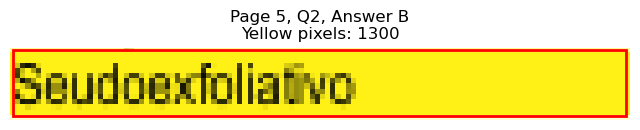

Page 5, Q2 - C: Detected box: x0=334.6, y0=139.9, x1=399.8, y1=152.6
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 316
Page 5, Q2, C: Yellow percentage: 0.0%


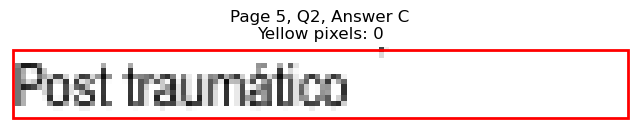

Page 5, Q2 - D: Detected box: x0=334.6, y0=152.5, x1=378.3, y1=165.2
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 233
Page 5, Q2, D: Yellow percentage: 0.0%


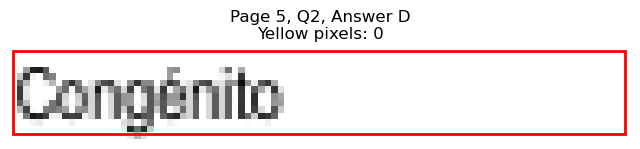


Page 5, Q2 - Selected Answer: B (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=75.4, y0=190.3, x1=118.5, y1=203.0
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 216
Page 5, Q3, A: Yellow percentage: 0.0%


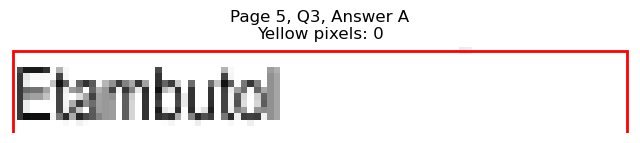

Page 5, Q3 - B: Detected box: x0=75.4, y0=202.9, x1=123.0, y1=215.6
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 248
Page 5, Q3, B: Yellow percentage: 0.0%


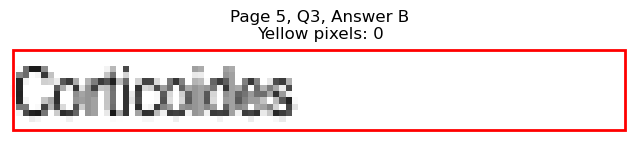

Page 5, Q3 - C: Detected box: x0=334.6, y0=190.3, x1=382.7, y1=203.0
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 339
Page 5, Q3, C: Yellow percentage: 0.0%


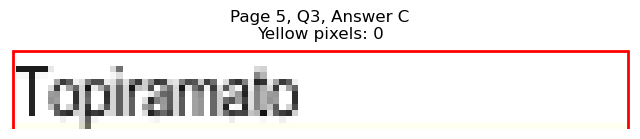

Page 5, Q3 - D: Detected box: x0=334.6, y0=202.9, x1=385.7, y1=215.6
Page 5, Q3, D: Yellow pixels: 1119
Page 5, Q3, D: Total non-white pixels: 1428
Page 5, Q3, D: Yellow percentage: 78.4%


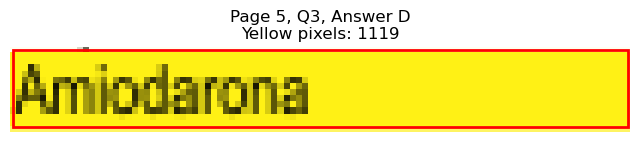


Page 5, Q3 - Selected Answer: D (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=75.4, y0=240.9, x1=116.5, y1=253.5
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 226
Page 5, Q4, A: Yellow percentage: 0.0%


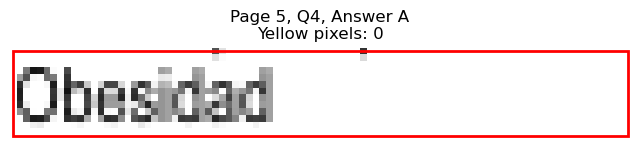

Page 5, Q4 - B: Detected box: x0=75.4, y0=253.5, x1=113.5, y1=266.1
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 213
Page 5, Q4, B: Yellow percentage: 0.0%


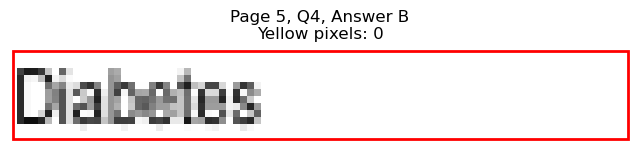

Page 5, Q4 - C: Detected box: x0=334.6, y0=240.9, x1=386.8, y1=253.5
Page 5, Q4, C: Yellow pixels: 1136
Page 5, Q4, C: Total non-white pixels: 1442
Page 5, Q4, C: Yellow percentage: 78.8%


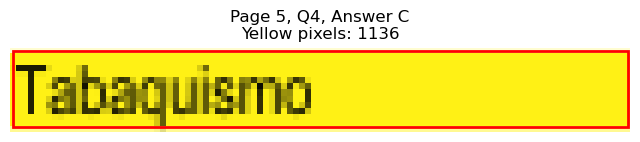

Page 5, Q4 - D: Detected box: x0=334.6, y0=253.5, x1=387.8, y1=266.1
Page 5, Q4, D: Yellow pixels: 104
Page 5, Q4, D: Total non-white pixels: 390
Page 5, Q4, D: Yellow percentage: 26.7%


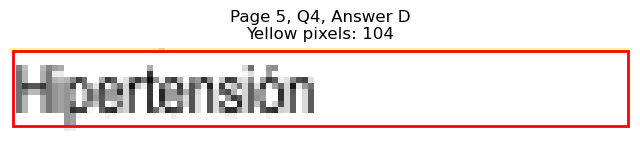


Page 5, Q4 - Selected Answer: C (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=75.4, y0=291.4, x1=216.9, y1=304.1
Page 5, Q5, A: Yellow pixels: 192
Page 5, Q5, A: Total non-white pixels: 885
Page 5, Q5, A: Yellow percentage: 21.7%


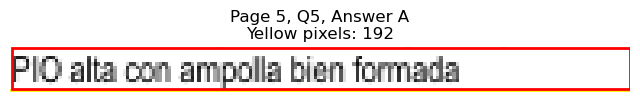

Page 5, Q5 - B: Detected box: x0=75.4, y0=304.0, x1=242.9, y1=316.7
Page 5, Q5, B: Yellow pixels: 2030
Page 5, Q5, B: Total non-white pixels: 2691
Page 5, Q5, B: Yellow percentage: 75.4%


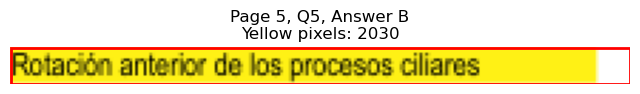

Page 5, Q5 - C: Detected box: x0=334.6, y0=291.4, x1=439.5, y1=304.1
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 540
Page 5, Q5, C: Yellow percentage: 0.0%


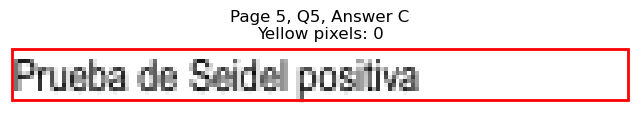

Page 5, Q5 - D: Detected box: x0=334.6, y0=304.0, x1=500.6, y1=316.7
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 811
Page 5, Q5, D: Yellow percentage: 0.0%


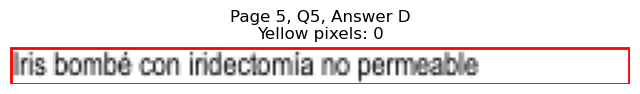


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=63.7, y0=354.5, x1=72.3, y1=367.2
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 48
Page 5, Q6, A: Yellow percentage: 0.0%


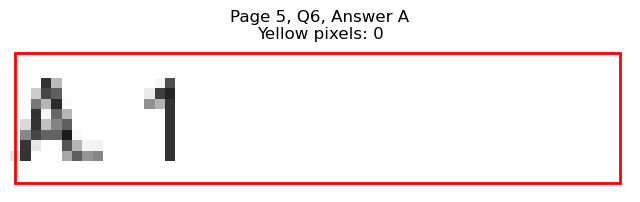

Page 5, Q6 - B: Detected box: x0=63.7, y0=367.1, x1=72.3, y1=379.8
Page 5, Q6, B: Yellow pixels: 0
Page 5, Q6, B: Total non-white pixels: 72
Page 5, Q6, B: Yellow percentage: 0.0%


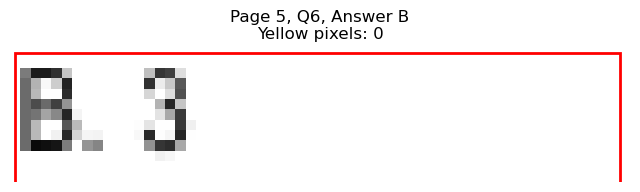

Page 5, Q6 - C: Detected box: x0=322.5, y0=354.5, x1=331.5, y1=367.2
Page 5, Q6, C: Yellow pixels: 733
Page 5, Q6, C: Total non-white pixels: 840
Page 5, Q6, C: Yellow percentage: 87.3%


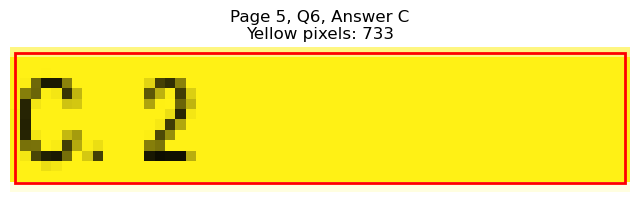

Page 5, Q6 - D: Detected box: x0=322.5, y0=367.1, x1=331.5, y1=379.8
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 129
Page 5, Q6, D: Yellow percentage: 0.0%


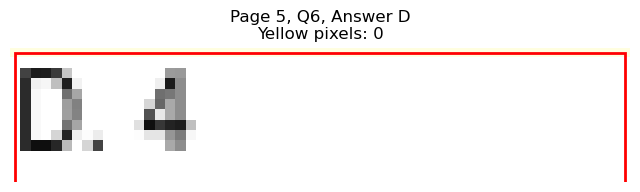


Page 5, Q6 - Selected Answer: C (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=75.4, y0=417.6, x1=105.0, y1=430.3
Page 5, Q7, A: Yellow pixels: 869
Page 5, Q7, A: Total non-white pixels: 1134
Page 5, Q7, A: Yellow percentage: 76.6%


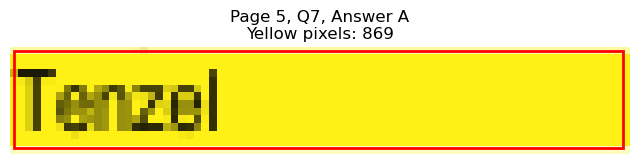

Page 5, Q7 - B: Detected box: x0=75.4, y0=430.2, x1=115.5, y1=442.9
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 311
Page 5, Q7, B: Yellow percentage: 0.0%


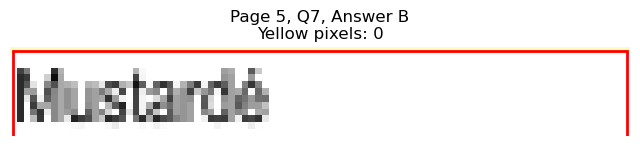

Page 5, Q7 - C: Detected box: x0=334.6, y0=417.6, x1=368.2, y1=430.3
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 185
Page 5, Q7, C: Yellow percentage: 0.0%


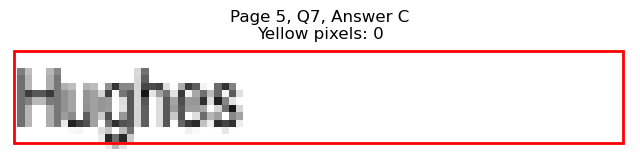

Page 5, Q7 - D: Detected box: x0=334.6, y0=430.2, x1=357.2, y1=442.9
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 111
Page 5, Q7, D: Yellow percentage: 0.0%


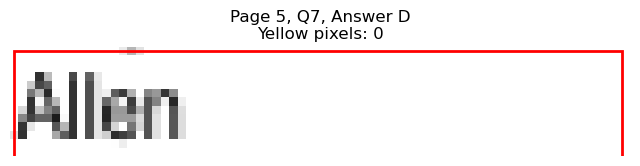


Page 5, Q7 - Selected Answer: A (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=75.4, y0=518.6, x1=214.7, y1=531.2
Page 5, Q8, A: Yellow pixels: 1921
Page 5, Q8, A: Total non-white pixels: 2660
Page 5, Q8, A: Yellow percentage: 72.2%


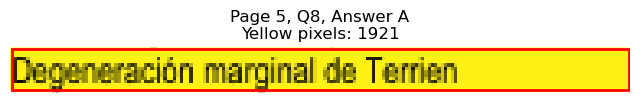

Page 5, Q8 - B: Detected box: x0=75.4, y0=531.2, x1=149.5, y1=543.8
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 491
Page 5, Q8, B: Yellow percentage: 0.0%


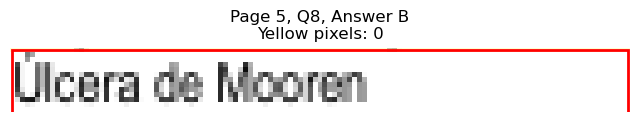

Page 5, Q8 - C: Detected box: x0=334.6, y0=518.6, x1=460.0, y1=531.2
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 630
Page 5, Q8, C: Yellow percentage: 0.0%


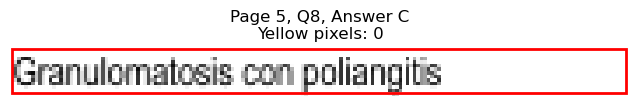

Page 5, Q8 - D: Detected box: x0=334.6, y0=531.2, x1=466.7, y1=543.8
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 700
Page 5, Q8, D: Yellow percentage: 0.0%


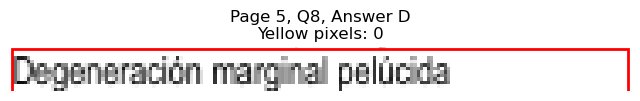


Page 5, Q8 - Selected Answer: A (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=75.4, y0=606.9, x1=151.6, y1=619.6
Page 5, Q9, A: Yellow pixels: 1356
Page 5, Q9, A: Total non-white pixels: 1778
Page 5, Q9, A: Yellow percentage: 76.3%


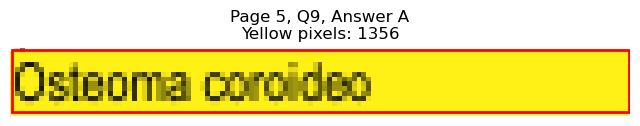

Page 5, Q9 - B: Detected box: x0=75.4, y0=619.6, x1=151.6, y1=632.3
Page 5, Q9, B: Yellow pixels: 127
Page 5, Q9, B: Total non-white pixels: 523
Page 5, Q9, B: Yellow percentage: 24.3%


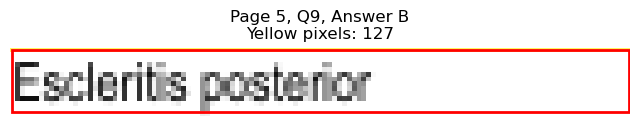

Page 5, Q9 - C: Detected box: x0=334.6, y0=606.9, x1=427.9, y1=619.6
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 469
Page 5, Q9, C: Yellow percentage: 0.0%


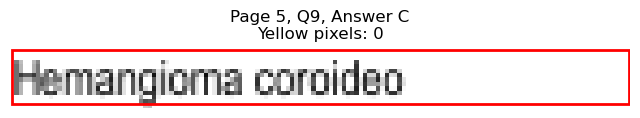

Page 5, Q9 - D: Detected box: x0=334.6, y0=619.6, x1=404.3, y1=632.3
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 356
Page 5, Q9, D: Yellow percentage: 0.0%


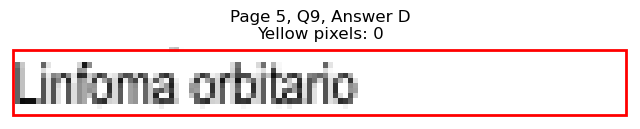


Page 5, Q9 - Selected Answer: A (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=75.4, y0=670.1, x1=103.9, y1=682.7
Page 5, Q10, A: Yellow pixels: 0
Page 5, Q10, A: Total non-white pixels: 147
Page 5, Q10, A: Yellow percentage: 0.0%


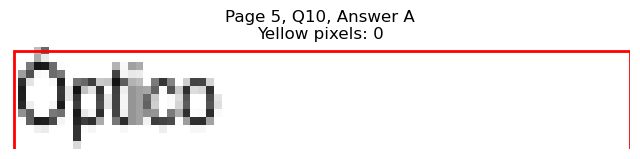

Page 5, Q10 - B: Detected box: x0=75.4, y0=682.7, x1=117.0, y1=695.3
Page 5, Q10, B: Yellow pixels: 0
Page 5, Q10, B: Total non-white pixels: 210
Page 5, Q10, B: Yellow percentage: 0.0%


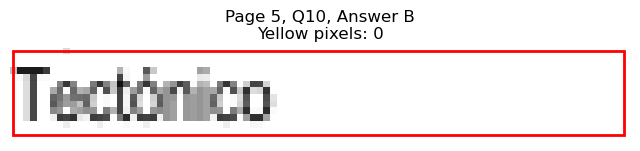

Page 5, Q10 - C: Detected box: x0=334.6, y0=670.1, x1=384.8, y1=682.7
Page 5, Q10, C: Yellow pixels: 1116
Page 5, Q10, C: Total non-white pixels: 1313
Page 5, Q10, C: Yellow percentage: 85.0%


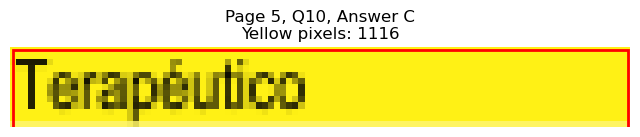

Page 5, Q10 - D: Detected box: x0=334.6, y0=682.7, x1=376.7, y1=695.3
Page 5, Q10, D: Yellow pixels: 93
Page 5, Q10, D: Total non-white pixels: 321
Page 5, Q10, D: Yellow percentage: 29.0%


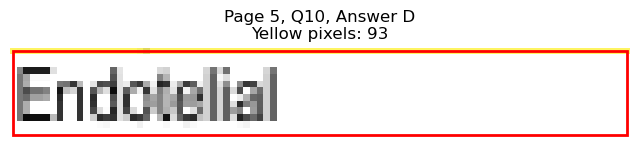


Page 5, Q10 - Selected Answer: C (based on yellow pixel count)




Page 5, Q11 - A: Detected box: x0=75.4, y0=720.6, x1=165.6, y1=733.2
Page 5, Q11, A: Yellow pixels: 0
Page 5, Q11, A: Total non-white pixels: 467
Page 5, Q11, A: Yellow percentage: 0.0%


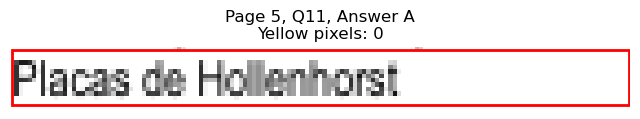

Page 5, Q11 - B: Detected box: x0=75.4, y0=733.2, x1=147.1, y1=745.8
Page 5, Q11, B: Yellow pixels: 0
Page 5, Q11, B: Total non-white pixels: 347
Page 5, Q11, B: Yellow percentage: 0.0%


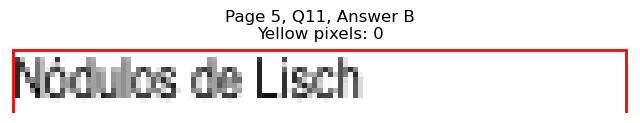

Page 5, Q11 - C: Detected box: x0=334.6, y0=720.6, x1=436.4, y1=733.2
Page 5, Q11, C: Yellow pixels: 153
Page 5, Q11, C: Total non-white pixels: 657
Page 5, Q11, C: Yellow percentage: 23.3%


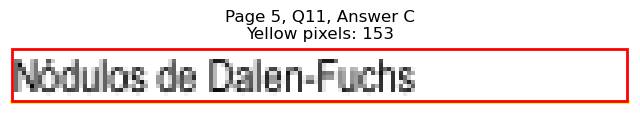

Page 5, Q11 - D: Detected box: x0=334.6, y0=733.2, x1=405.4, y1=745.8
Page 5, Q11, D: Yellow pixels: 1303
Page 5, Q11, D: Total non-white pixels: 1586
Page 5, Q11, D: Yellow percentage: 82.2%


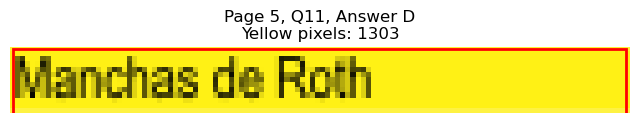


Page 5, Q11 - Selected Answer: D (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=75.4, y0=102.0, x1=83.9, y1=114.7
Page 6, Q1, A: Yellow pixels: 746
Page 6, Q1, A: Total non-white pixels: 767
Page 6, Q1, A: Yellow percentage: 97.3%


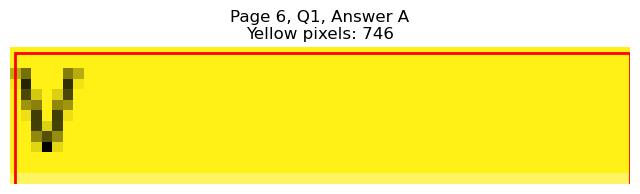

Page 6, Q1 - B: Detected box: x0=75.4, y0=114.6, x1=83.9, y1=127.3
Page 6, Q1, B: Yellow pixels: 59
Page 6, Q1, B: Total non-white pixels: 90
Page 6, Q1, B: Yellow percentage: 65.6%


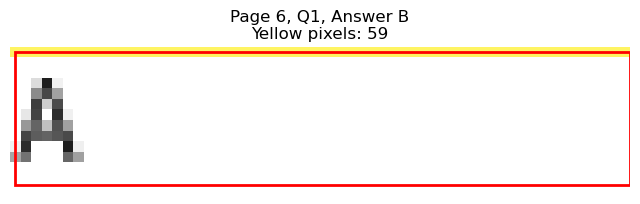

Page 6, Q1 - C: Detected box: x0=322.5, y0=102.0, x1=331.5, y1=114.7
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 68
Page 6, Q1, C: Yellow percentage: 0.0%


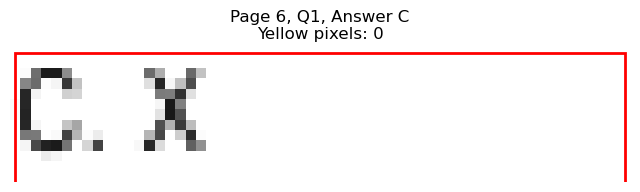

Page 6, Q1 - D: Detected box: x0=322.5, y0=114.6, x1=331.5, y1=127.3
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 66
Page 6, Q1, D: Yellow percentage: 0.0%


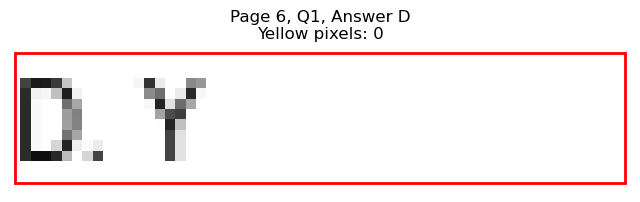


Page 6, Q1 - Selected Answer: A (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=75.4, y0=165.1, x1=195.3, y1=177.8
Page 6, Q2, A: Yellow pixels: 1712
Page 6, Q2, A: Total non-white pixels: 2223
Page 6, Q2, A: Yellow percentage: 77.0%


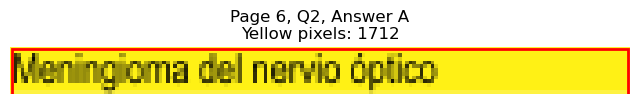

Page 6, Q2 - B: Detected box: x0=75.4, y0=177.7, x1=222.9, y1=190.4
Page 6, Q2, B: Yellow pixels: 197
Page 6, Q2, B: Total non-white pixels: 916
Page 6, Q2, B: Yellow percentage: 21.5%


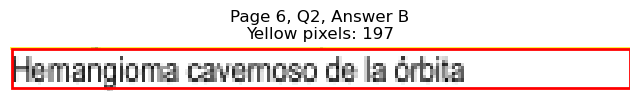

Page 6, Q2 - C: Detected box: x0=334.6, y0=165.1, x1=462.5, y1=177.8
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 658
Page 6, Q2, C: Yellow percentage: 0.0%


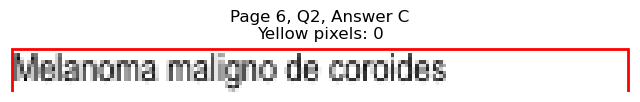

Page 6, Q2 - D: Detected box: x0=334.6, y0=177.7, x1=434.0, y1=190.4
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 494
Page 6, Q2, D: Yellow percentage: 0.0%


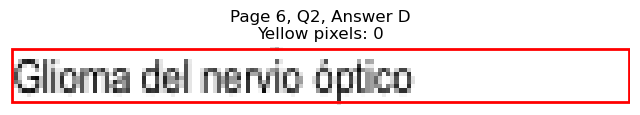


Page 6, Q2 - Selected Answer: A (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=75.4, y0=228.3, x1=220.8, y1=240.9
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 717
Page 6, Q3, A: Yellow percentage: 0.0%


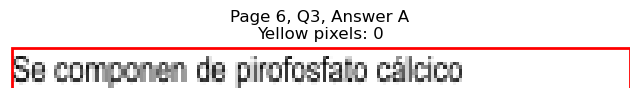

Page 6, Q3 - B: Detected box: x0=75.4, y0=240.9, x1=192.3, y1=253.5
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 574
Page 6, Q3, B: Yellow percentage: 0.0%


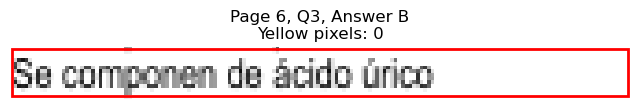

Page 6, Q3 - C: Detected box: x0=334.6, y0=228.3, x1=481.7, y1=240.9
Page 6, Q3, C: Yellow pixels: 1991
Page 6, Q3, C: Total non-white pixels: 2574
Page 6, Q3, C: Yellow percentage: 77.4%


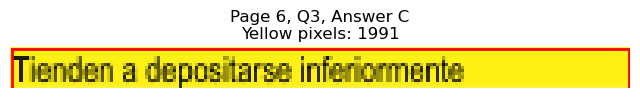

Page 6, Q3 - D: Detected box: x0=334.6, y0=240.9, x1=480.2, y1=253.5
Page 6, Q3, D: Yellow pixels: 196
Page 6, Q3, D: Total non-white pixels: 877
Page 6, Q3, D: Yellow percentage: 22.3%


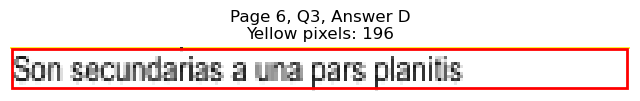


Page 6, Q3 - Selected Answer: C (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=75.4, y0=304.0, x1=200.8, y1=316.7
Page 6, Q4, A: Yellow pixels: 1810
Page 6, Q4, A: Total non-white pixels: 2288
Page 6, Q4, A: Yellow percentage: 79.1%


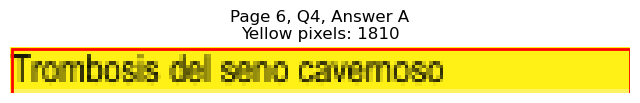

Page 6, Q4 - B: Detected box: x0=75.4, y0=316.6, x1=192.3, y1=329.3
Page 6, Q4, B: Yellow pixels: 168
Page 6, Q4, B: Total non-white pixels: 732
Page 6, Q4, B: Yellow percentage: 23.0%


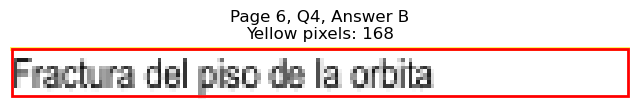

Page 6, Q4 - C: Detected box: x0=334.6, y0=304.0, x1=428.9, y1=316.7
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 436
Page 6, Q4, C: Yellow percentage: 0.0%


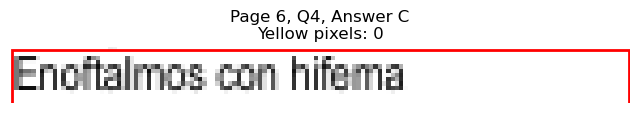

Page 6, Q4 - D: Detected box: x0=334.6, y0=316.6, x1=437.0, y1=329.3
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 500
Page 6, Q4, D: Yellow percentage: 0.0%


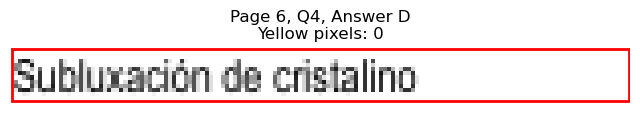


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=75.4, y0=354.5, x1=166.1, y1=367.2
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 421
Page 6, Q5, A: Yellow percentage: 0.0%


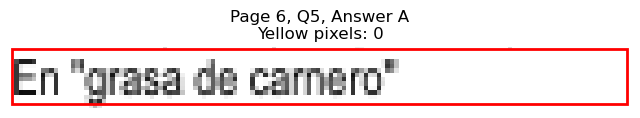

Page 6, Q5 - B: Detected box: x0=75.4, y0=367.1, x1=198.3, y1=379.8
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 622
Page 6, Q5, B: Yellow percentage: 0.0%


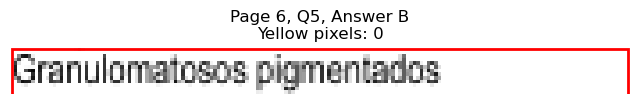

Page 6, Q5 - C: Detected box: x0=334.6, y0=354.5, x1=412.9, y1=367.2
Page 6, Q5, C: Yellow pixels: 1372
Page 6, Q5, C: Total non-white pixels: 1806
Page 6, Q5, C: Yellow percentage: 76.0%


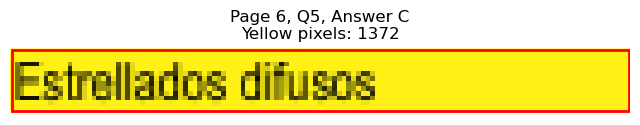

Page 6, Q5 - D: Detected box: x0=334.6, y0=367.1, x1=417.9, y1=379.8
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 572
Page 6, Q5, D: Yellow percentage: 0.0%


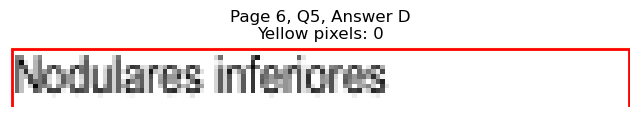


Page 6, Q5 - Selected Answer: C (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=75.4, y0=430.2, x1=144.0, y1=442.9
Page 6, Q6, A: Yellow pixels: 1292
Page 6, Q6, A: Total non-white pixels: 1560
Page 6, Q6, A: Yellow percentage: 82.8%


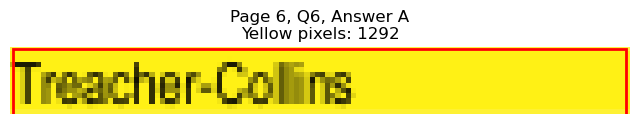

Page 6, Q6 - B: Detected box: x0=75.4, y0=442.8, x1=127.0, y1=455.5
Page 6, Q6, B: Yellow pixels: 102
Page 6, Q6, B: Total non-white pixels: 359
Page 6, Q6, B: Yellow percentage: 28.4%


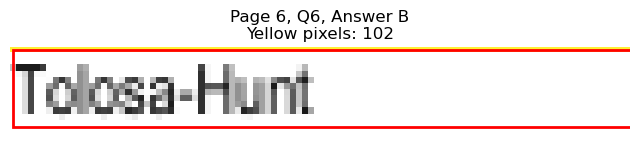

Page 6, Q6 - C: Detected box: x0=334.6, y0=430.2, x1=401.3, y1=442.9
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 355
Page 6, Q6, C: Yellow percentage: 0.0%


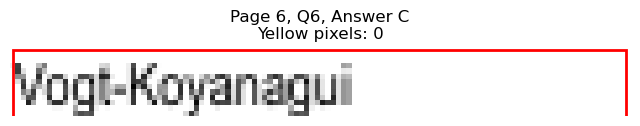

Page 6, Q6 - D: Detected box: x0=334.6, y0=442.8, x1=393.3, y1=455.5
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 333
Page 6, Q6, D: Yellow percentage: 0.0%


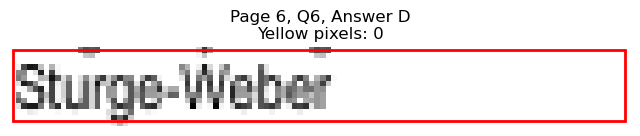


Page 6, Q6 - Selected Answer: A (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=75.4, y0=480.8, x1=140.6, y1=493.4
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 574
Page 6, Q7, A: Yellow percentage: 0.0%


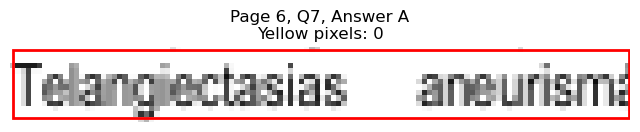

Page 6, Q7 - B: Detected box: x0=75.4, y0=506.0, x1=229.8, y1=518.6
Page 6, Q7, B: Yellow pixels: 2062
Page 6, Q7, B: Total non-white pixels: 2870
Page 6, Q7, B: Yellow percentage: 71.8%


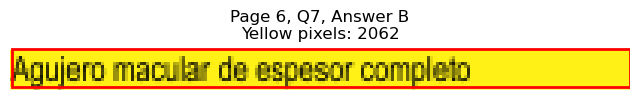

Page 6, Q7 - C: Detected box: x0=334.6, y0=480.8, x1=541.2, y1=493.4
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 1035
Page 6, Q7, C: Yellow percentage: 0.0%


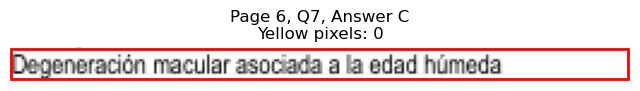

Page 6, Q7 - D: Detected box: x0=334.6, y0=493.4, x1=463.5, y1=506.0
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 656
Page 6, Q7, D: Yellow percentage: 0.0%


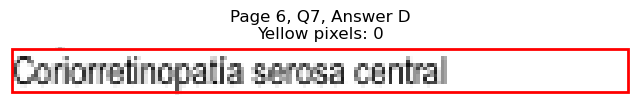


Page 6, Q7 - Selected Answer: B (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=217.8, y0=569.1, x1=259.4, y1=581.8
Page 6, Q8, A: Yellow pixels: 600
Page 6, Q8, A: Total non-white pixels: 845
Page 6, Q8, A: Yellow percentage: 71.0%


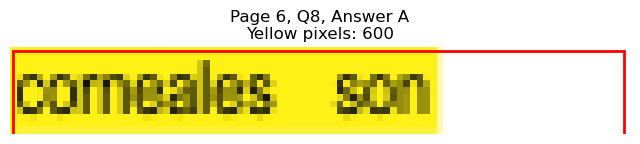

Page 6, Q8 - B: Detected box: x0=75.4, y0=594.3, x1=282.4, y1=607.0
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 1262
Page 6, Q8, B: Yellow percentage: 0.0%


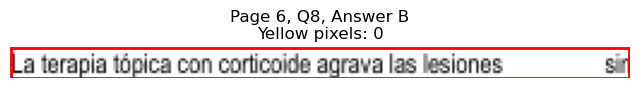

Page 6, Q8 - C: Detected box: x0=334.6, y0=569.1, x1=516.2, y1=581.8
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 922
Page 6, Q8, C: Yellow percentage: 0.0%


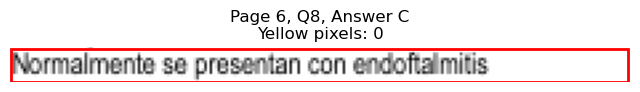

Page 6, Q8 - D: Detected box: x0=391.8, y0=581.7, x1=452.5, y1=594.4
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 537
Page 6, Q8, D: Yellow percentage: 0.0%


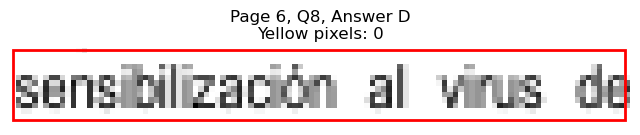


Page 6, Q8 - Selected Answer: A (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=75.4, y0=644.9, x1=119.1, y1=657.5
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 232
Page 6, Q9, A: Yellow percentage: 0.0%


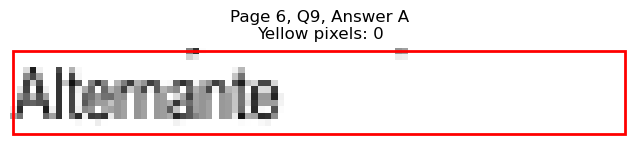

Page 6, Q9 - B: Detected box: x0=75.4, y0=657.5, x1=115.5, y1=670.1
Page 6, Q9, B: Yellow pixels: 0
Page 6, Q9, B: Total non-white pixels: 206
Page 6, Q9, B: Yellow percentage: 0.0%


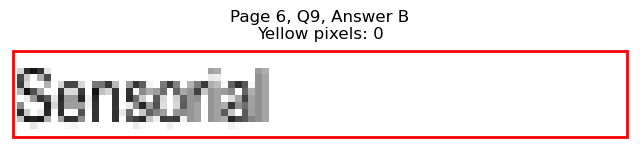

Page 6, Q9 - C: Detected box: x0=334.6, y0=644.9, x1=386.8, y1=657.5
Page 6, Q9, C: Yellow pixels: 103
Page 6, Q9, C: Total non-white pixels: 363
Page 6, Q9, C: Yellow percentage: 28.4%


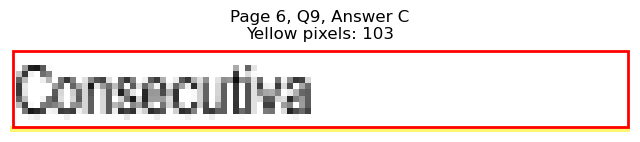

Page 6, Q9 - D: Detected box: x0=334.6, y0=657.5, x1=384.8, y1=670.1
Page 6, Q9, D: Yellow pixels: 1108
Page 6, Q9, D: Total non-white pixels: 1414
Page 6, Q9, D: Yellow percentage: 78.4%


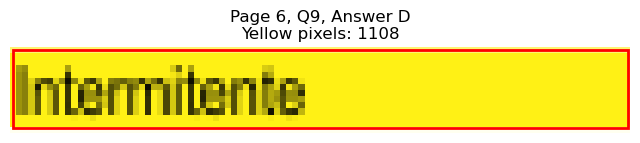


Page 6, Q9 - Selected Answer: D (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=75.4, y0=695.4, x1=146.5, y1=708.0
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 385
Page 6, Q10, A: Yellow percentage: 0.0%


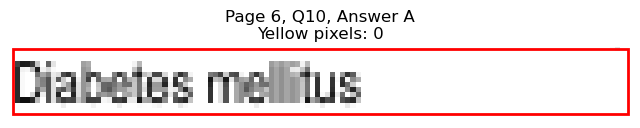

Page 6, Q10 - B: Detected box: x0=75.4, y0=708.0, x1=135.0, y1=720.6
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 302
Page 6, Q10, B: Yellow percentage: 0.0%


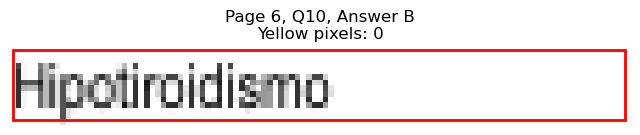

Page 6, Q10 - C: Detected box: x0=334.6, y0=695.4, x1=411.9, y1=708.0
Page 6, Q10, C: Yellow pixels: 128
Page 6, Q10, C: Total non-white pixels: 679
Page 6, Q10, C: Yellow percentage: 18.9%


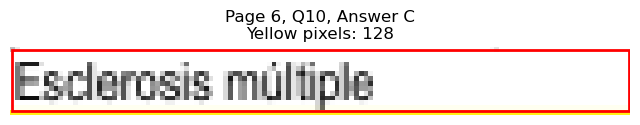

Page 6, Q10 - D: Detected box: x0=334.6, y0=708.0, x1=410.8, y1=720.6
Page 6, Q10, D: Yellow pixels: 1354
Page 6, Q10, D: Total non-white pixels: 1778
Page 6, Q10, D: Yellow percentage: 76.2%


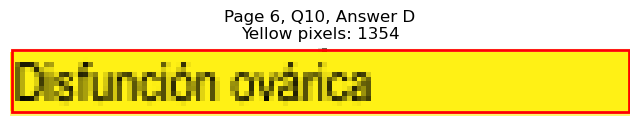


Page 6, Q10 - Selected Answer: D (based on yellow pixel count)





Page 7: Found 11 questions
Page 7, Q1 - A: Detected box: x0=75.4, y0=102.0, x1=124.0, y1=114.7
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 226
Page 7, Q1, A: Yellow percentage: 0.0%


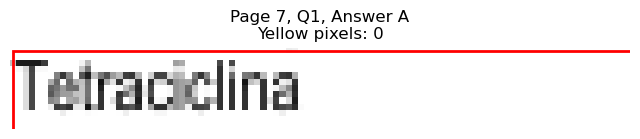

Page 7, Q1 - B: Detected box: x0=75.4, y0=114.6, x1=128.5, y1=127.3
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 262
Page 7, Q1, B: Yellow percentage: 0.0%


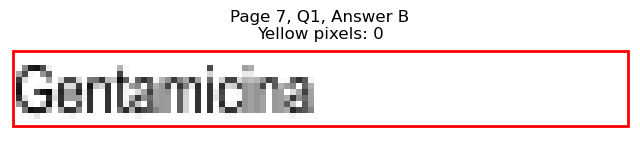

Page 7, Q1 - C: Detected box: x0=334.6, y0=102.0, x1=389.8, y1=114.7
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 393
Page 7, Q1, C: Yellow percentage: 0.0%


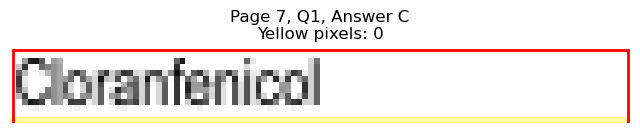

Page 7, Q1 - D: Detected box: x0=334.6, y0=114.6, x1=394.3, y1=127.3
Page 7, Q1, D: Yellow pixels: 1097
Page 7, Q1, D: Total non-white pixels: 1554
Page 7, Q1, D: Yellow percentage: 70.6%


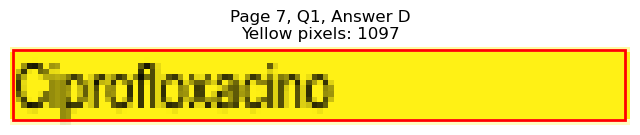


Page 7, Q1 - Selected Answer: D (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=75.4, y0=165.1, x1=170.2, y1=177.8
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 484
Page 7, Q2, A: Yellow percentage: 0.0%


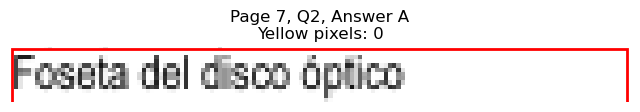

Page 7, Q2 - B: Detected box: x0=75.4, y0=177.7, x1=174.6, y1=190.4
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 472
Page 7, Q2, B: Yellow percentage: 0.0%


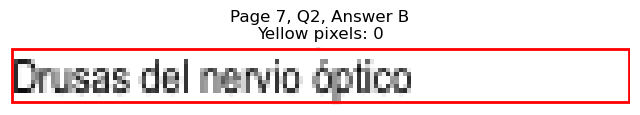

Page 7, Q2 - C: Detected box: x0=334.6, y0=165.1, x1=394.3, y1=177.8
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 432
Page 7, Q2, C: Yellow percentage: 0.0%


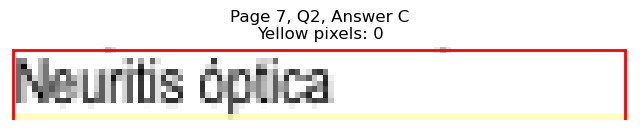

Page 7, Q2 - D: Detected box: x0=334.6, y0=177.7, x1=447.4, y1=190.4
Page 7, Q2, D: Yellow pixels: 1501
Page 7, Q2, D: Total non-white pixels: 2296
Page 7, Q2, D: Yellow percentage: 65.4%


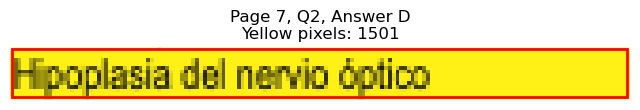


Page 7, Q2 - Selected Answer: D (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=75.4, y0=240.9, x1=161.7, y1=253.5
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 473
Page 7, Q3, A: Yellow percentage: 0.0%


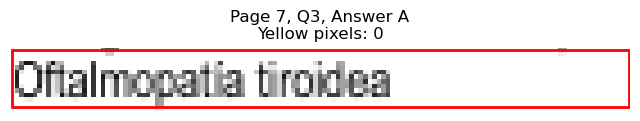

Page 7, Q3 - B: Detected box: x0=75.4, y0=253.5, x1=134.5, y1=266.1
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 316
Page 7, Q3, B: Yellow percentage: 0.0%


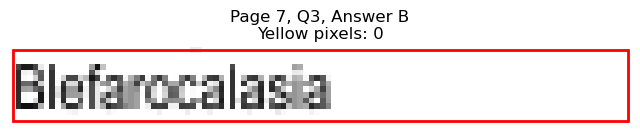

Page 7, Q3 - C: Detected box: x0=334.6, y0=240.9, x1=458.0, y1=253.5
Page 7, Q3, C: Yellow pixels: 1784
Page 7, Q3, C: Total non-white pixels: 2436
Page 7, Q3, C: Yellow percentage: 73.2%


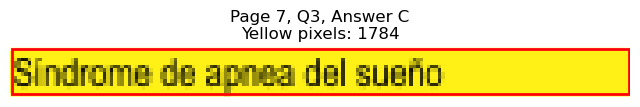

Page 7, Q3 - D: Detected box: x0=334.6, y0=253.5, x1=466.7, y1=266.1
Page 7, Q3, D: Yellow pixels: 183
Page 7, Q3, D: Total non-white pixels: 865
Page 7, Q3, D: Yellow percentage: 21.2%


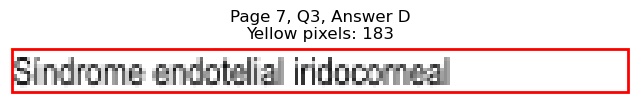


Page 7, Q3 - Selected Answer: C (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=75.4, y0=316.6, x1=125.5, y1=329.3
Page 7, Q4, A: Yellow pixels: 1012
Page 7, Q4, A: Total non-white pixels: 1414
Page 7, Q4, A: Yellow percentage: 71.6%


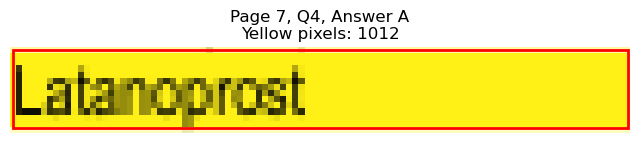

Page 7, Q4 - B: Detected box: x0=75.4, y0=329.2, x1=106.9, y1=341.9
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 227
Page 7, Q4, B: Yellow percentage: 0.0%


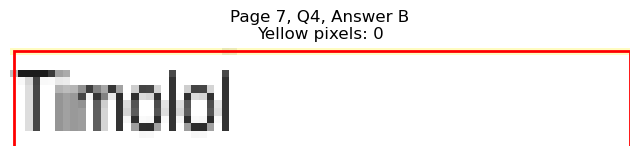

Page 7, Q4 - C: Detected box: x0=334.6, y0=316.6, x1=387.8, y1=329.3
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 275
Page 7, Q4, C: Yellow percentage: 0.0%


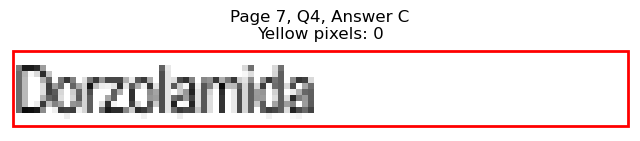

Page 7, Q4 - D: Detected box: x0=334.6, y0=329.2, x1=374.2, y1=341.9
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 212
Page 7, Q4, D: Yellow percentage: 0.0%


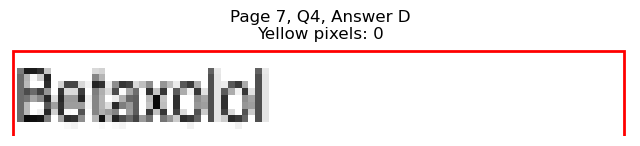


Page 7, Q4 - Selected Answer: A (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=75.4, y0=392.3, x1=160.6, y1=405.0
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 445
Page 7, Q5, A: Yellow percentage: 0.0%


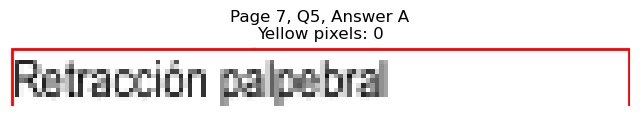

Page 7, Q5 - B: Detected box: x0=75.4, y0=404.9, x1=163.1, y1=417.6
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 489
Page 7, Q5, B: Yellow percentage: 0.0%


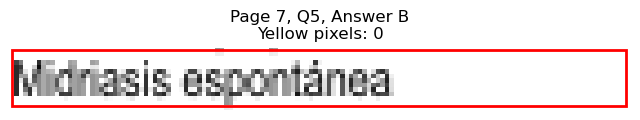

Page 7, Q5 - C: Detected box: x0=334.6, y0=392.3, x1=448.5, y1=405.0
Page 7, Q5, C: Yellow pixels: 1694
Page 7, Q5, C: Total non-white pixels: 2145
Page 7, Q5, C: Yellow percentage: 79.0%


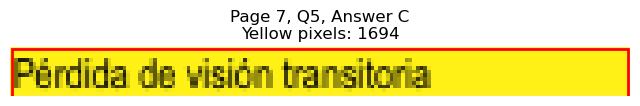

Page 7, Q5 - D: Detected box: x0=334.6, y0=404.9, x1=439.4, y1=417.6
Page 7, Q5, D: Yellow pixels: 156
Page 7, Q5, D: Total non-white pixels: 710
Page 7, Q5, D: Yellow percentage: 22.0%


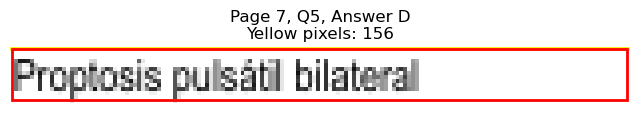


Page 7, Q5 - Selected Answer: C (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=75.4, y0=442.8, x1=113.5, y1=455.5
Page 7, Q6, A: Yellow pixels: 996
Page 7, Q6, A: Total non-white pixels: 1246
Page 7, Q6, A: Yellow percentage: 79.9%


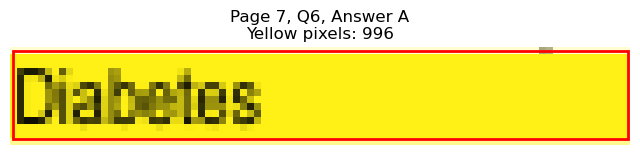

Page 7, Q6 - B: Detected box: x0=75.4, y0=455.5, x1=121.0, y1=468.1
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 198
Page 7, Q6, B: Yellow percentage: 0.0%


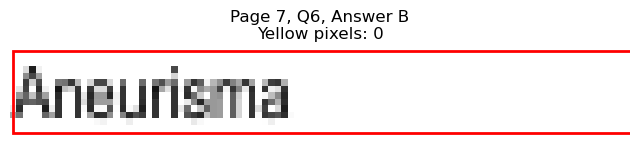

Page 7, Q6 - C: Detected box: x0=334.6, y0=442.8, x1=377.2, y1=455.5
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 245
Page 7, Q6, C: Yellow percentage: 0.0%


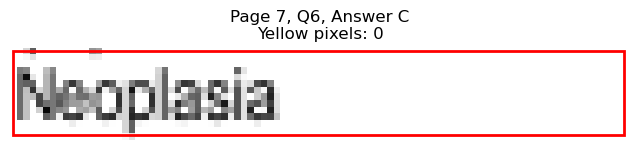

Page 7, Q6 - D: Detected box: x0=334.6, y0=455.5, x1=381.3, y1=468.1
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 243
Page 7, Q6, D: Yellow percentage: 0.0%


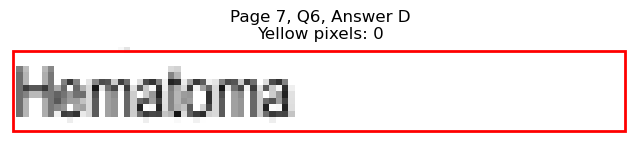


Page 7, Q6 - Selected Answer: A (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=63.7, y0=506.0, x1=72.3, y1=518.6
Page 7, Q7, A: Yellow pixels: 60
Page 7, Q7, A: Total non-white pixels: 135
Page 7, Q7, A: Yellow percentage: 44.4%


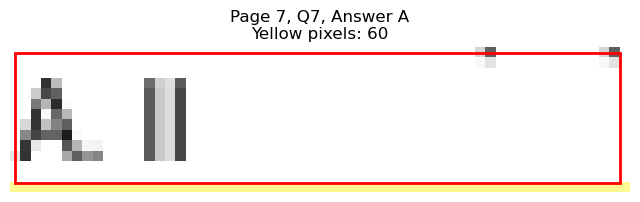

Page 7, Q7 - B: Detected box: x0=63.7, y0=518.6, x1=72.3, y1=531.2
Page 7, Q7, B: Yellow pixels: 727
Page 7, Q7, B: Total non-white pixels: 840
Page 7, Q7, B: Yellow percentage: 86.5%


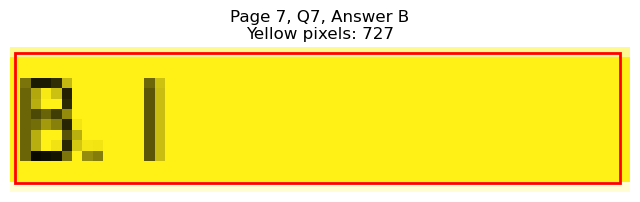

Page 7, Q7 - C: Detected box: x0=334.6, y0=506.0, x1=344.7, y1=518.6
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 40
Page 7, Q7, C: Yellow percentage: 0.0%


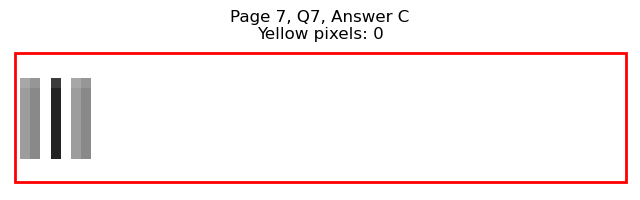

Page 7, Q7 - D: Detected box: x0=334.6, y0=518.6, x1=345.7, y1=531.2
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 44
Page 7, Q7, D: Yellow percentage: 0.0%


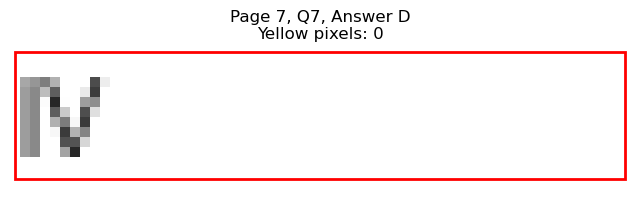


Page 7, Q7 - Selected Answer: B (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=75.4, y0=556.5, x1=387.4, y1=569.2
Page 7, Q8, A: Yellow pixels: 363
Page 7, Q8, A: Total non-white pixels: 1894
Page 7, Q8, A: Yellow percentage: 19.2%


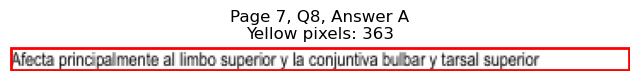

Page 7, Q8 - B: Detected box: x0=75.4, y0=569.1, x1=385.9, y1=581.8
Page 7, Q8, B: Yellow pixels: 3478
Page 7, Q8, B: Total non-white pixels: 4693
Page 7, Q8, B: Yellow percentage: 74.1%


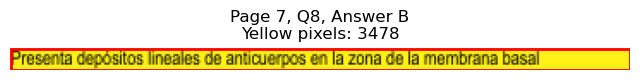

Page 7, Q8 - C: Detected box: x0=75.9, y0=581.7, x1=405.5, y1=594.4
Page 7, Q8, C: Yellow pixels: 381
Page 7, Q8, C: Total non-white pixels: 2097
Page 7, Q8, C: Yellow percentage: 18.2%


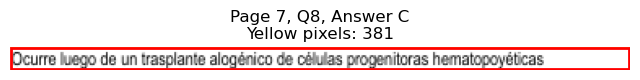

Page 7, Q8 - D: Detected box: x0=75.9, y0=594.3, x1=376.9, y1=607.0
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 1506
Page 7, Q8, D: Yellow percentage: 0.0%


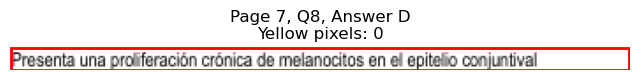


Page 7, Q8 - Selected Answer: B (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=75.4, y0=632.2, x1=122.5, y1=644.9
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 232
Page 7, Q9, A: Yellow percentage: 0.0%


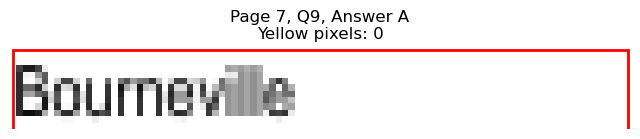

Page 7, Q9 - B: Detected box: x0=75.4, y0=644.9, x1=105.0, y1=657.5
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 148
Page 7, Q9, B: Yellow percentage: 0.0%


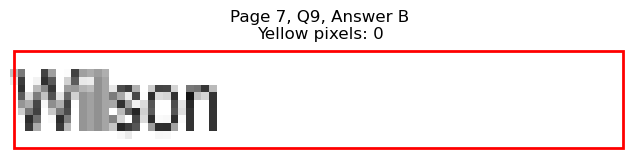

Page 7, Q9 - C: Detected box: x0=334.6, y0=632.2, x1=359.7, y1=644.9
Page 7, Q9, C: Yellow pixels: 893
Page 7, Q9, C: Total non-white pixels: 988
Page 7, Q9, C: Yellow percentage: 90.4%


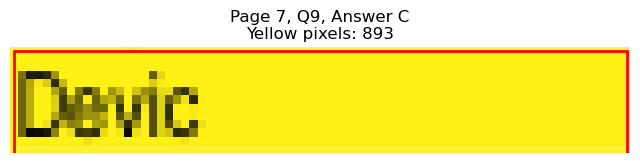

Page 7, Q9 - D: Detected box: x0=334.6, y0=644.9, x1=359.2, y1=657.5
Page 7, Q9, D: Yellow pixels: 0
Page 7, Q9, D: Total non-white pixels: 110
Page 7, Q9, D: Yellow percentage: 0.0%


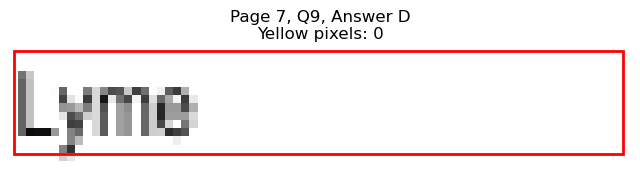


Page 7, Q9 - Selected Answer: C (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=75.4, y0=695.4, x1=169.2, y1=708.0
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 488
Page 7, Q10, A: Yellow percentage: 0.0%


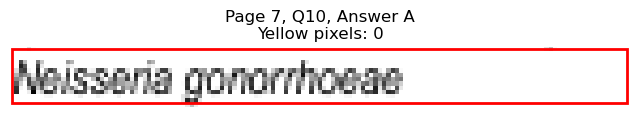

Page 7, Q10 - B: Detected box: x0=75.4, y0=708.0, x1=182.7, y1=720.6
Page 7, Q10, B: Yellow pixels: 0
Page 7, Q10, B: Total non-white pixels: 542
Page 7, Q10, B: Yellow percentage: 0.0%


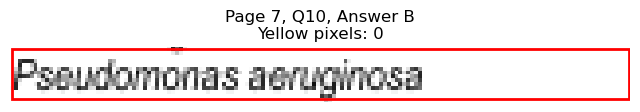

Page 7, Q10 - C: Detected box: x0=334.6, y0=695.4, x1=399.8, y1=708.0
Page 7, Q10, C: Yellow pixels: 116
Page 7, Q10, C: Total non-white pixels: 562
Page 7, Q10, C: Yellow percentage: 20.6%


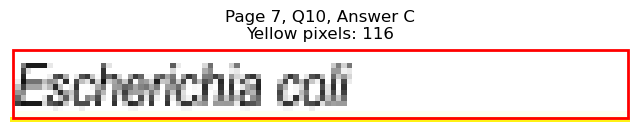

Page 7, Q10 - D: Detected box: x0=334.6, y0=708.0, x1=436.4, y1=720.6
Page 7, Q10, D: Yellow pixels: 1582
Page 7, Q10, D: Total non-white pixels: 2142
Page 7, Q10, D: Yellow percentage: 73.9%


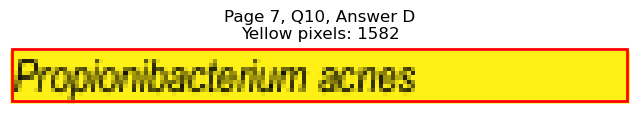


Page 7, Q10 - Selected Answer: D (based on yellow pixel count)




Page 7, Q11 - A: Detected box: x0=75.4, y0=745.8, x1=162.1, y1=758.4
Page 7, Q11, A: Yellow pixels: 0
Page 7, Q11, A: Total non-white pixels: 418
Page 7, Q11, A: Yellow percentage: 0.0%


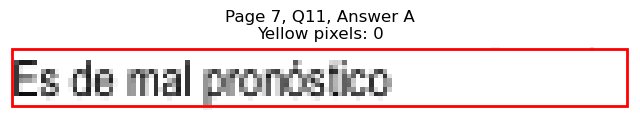

Page 7, Q11 - B: Detected box: x0=75.4, y0=758.5, x1=181.7, y1=771.2
Page 7, Q11, B: Yellow pixels: 0
Page 7, Q11, B: Total non-white pixels: 524
Page 7, Q11, B: Yellow percentage: 0.0%


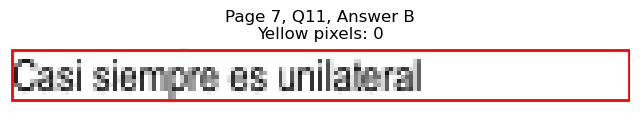

Page 7, Q11 - C: Detected box: x0=334.6, y0=745.8, x1=456.5, y1=758.4
Page 7, Q11, C: Yellow pixels: 1788
Page 7, Q11, C: Total non-white pixels: 2422
Page 7, Q11, C: Yellow percentage: 73.8%


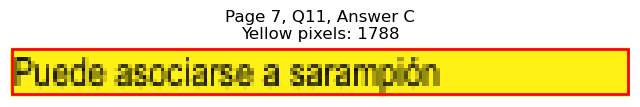

Page 7, Q11 - D: Detected box: x0=334.6, y0=758.5, x1=451.5, y1=771.2
Page 7, Q11, D: Yellow pixels: 168
Page 7, Q11, D: Total non-white pixels: 732
Page 7, Q11, D: Yellow percentage: 23.0%


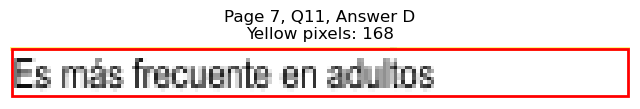


Page 7, Q11 - Selected Answer: C (based on yellow pixel count)





Page 8: Found 12 questions
Page 8, Q1 - A: Detected box: x0=75.4, y0=89.4, x1=123.5, y1=102.1
Page 8, Q1, A: Yellow pixels: 99
Page 8, Q1, A: Total non-white pixels: 357
Page 8, Q1, A: Yellow percentage: 27.7%


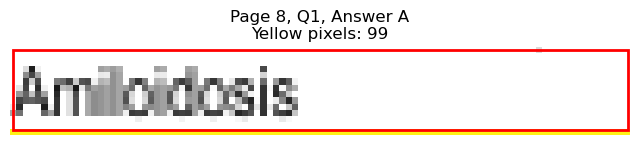

Page 8, Q1 - B: Detected box: x0=75.4, y0=102.0, x1=171.7, y1=114.7
Page 8, Q1, B: Yellow pixels: 1548
Page 8, Q1, B: Total non-white pixels: 1911
Page 8, Q1, B: Yellow percentage: 81.0%


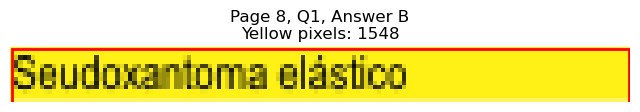

Page 8, Q1 - C: Detected box: x0=334.6, y0=89.4, x1=411.3, y1=102.1
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 412
Page 8, Q1, C: Yellow percentage: 0.0%


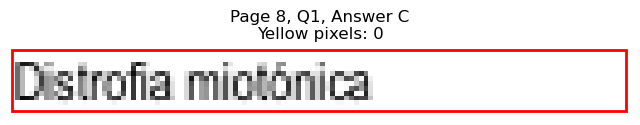

Page 8, Q1 - D: Detected box: x0=334.6, y0=102.0, x1=404.3, y1=114.7
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 347
Page 8, Q1, D: Yellow percentage: 0.0%


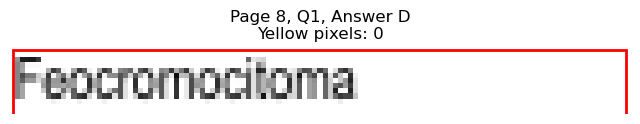


Page 8, Q1 - Selected Answer: B (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=75.4, y0=139.9, x1=116.5, y1=152.6
Page 8, Q2, A: Yellow pixels: 92
Page 8, Q2, A: Total non-white pixels: 318
Page 8, Q2, A: Yellow percentage: 28.9%


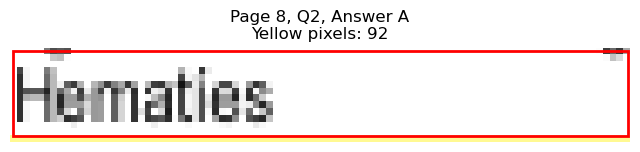

Page 8, Q2 - B: Detected box: x0=75.4, y0=152.5, x1=125.1, y1=165.2
Page 8, Q2, B: Yellow pixels: 1098
Page 8, Q2, B: Total non-white pixels: 1414
Page 8, Q2, B: Yellow percentage: 77.7%


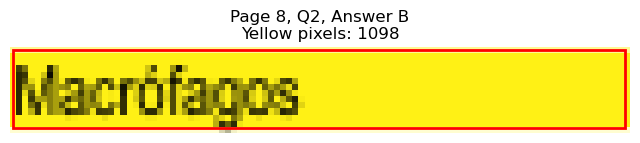

Page 8, Q2 - C: Detected box: x0=334.6, y0=139.9, x1=375.3, y1=152.6
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 216
Page 8, Q2, C: Yellow percentage: 0.0%


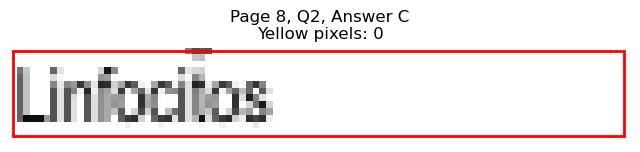

Page 8, Q2 - D: Detected box: x0=334.6, y0=152.5, x1=380.2, y1=165.2
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 245
Page 8, Q2, D: Yellow percentage: 0.0%


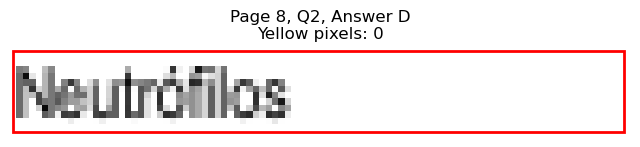


Page 8, Q2 - Selected Answer: B (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=63.7, y0=202.9, x1=72.3, y1=215.6
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 52
Page 8, Q3, A: Yellow percentage: 0.0%


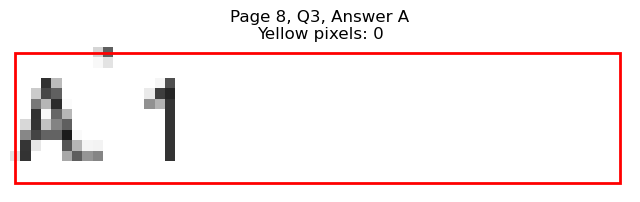

Page 8, Q3 - B: Detected box: x0=63.7, y0=215.7, x1=72.3, y1=228.3
Page 8, Q3, B: Yellow pixels: 664
Page 8, Q3, B: Total non-white pixels: 840
Page 8, Q3, B: Yellow percentage: 79.0%


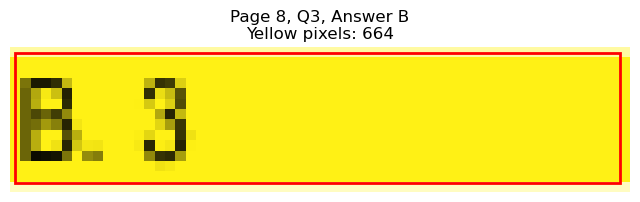

Page 8, Q3 - C: Detected box: x0=322.5, y0=202.9, x1=331.5, y1=215.6
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 62
Page 8, Q3, C: Yellow percentage: 0.0%


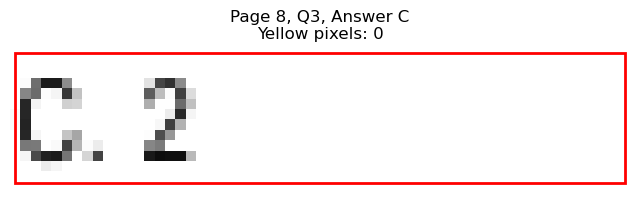

Page 8, Q3 - D: Detected box: x0=322.5, y0=215.7, x1=331.5, y1=228.3
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 69
Page 8, Q3, D: Yellow percentage: 0.0%


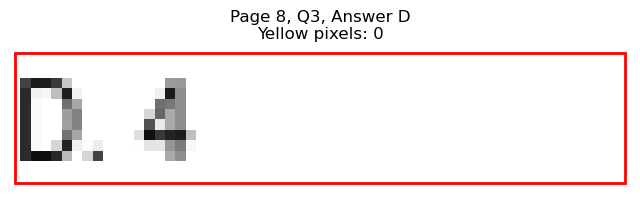


Page 8, Q3 - Selected Answer: B (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=75.4, y0=253.5, x1=126.5, y1=266.1
Page 8, Q4, A: Yellow pixels: 1095
Page 8, Q4, A: Total non-white pixels: 1428
Page 8, Q4, A: Yellow percentage: 76.7%


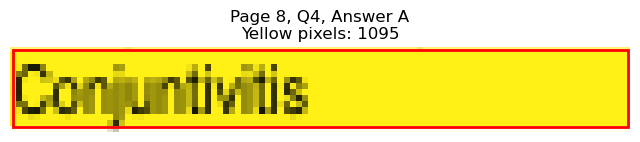

Page 8, Q4 - B: Detected box: x0=75.4, y0=266.1, x1=109.9, y1=278.7
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 261
Page 8, Q4, B: Yellow percentage: 0.0%


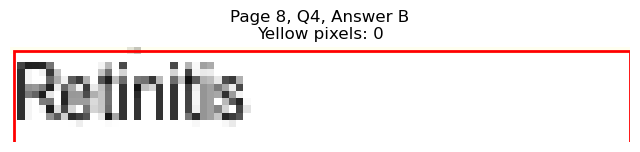

Page 8, Q4 - C: Detected box: x0=334.6, y0=253.5, x1=388.7, y1=266.1
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 279
Page 8, Q4, C: Yellow percentage: 0.0%


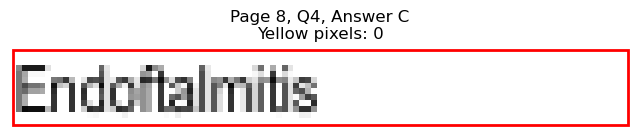

Page 8, Q4 - D: Detected box: x0=334.6, y0=266.1, x1=373.3, y1=278.7
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 214
Page 8, Q4, D: Yellow percentage: 0.0%


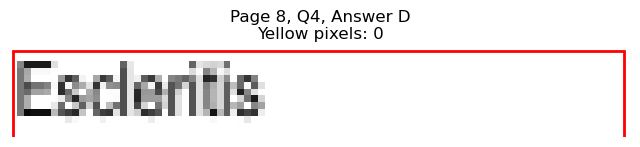


Page 8, Q4 - Selected Answer: A (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=75.4, y0=316.6, x1=135.5, y1=329.3
Page 8, Q5, A: Yellow pixels: 111
Page 8, Q5, A: Total non-white pixels: 415
Page 8, Q5, A: Yellow percentage: 26.7%


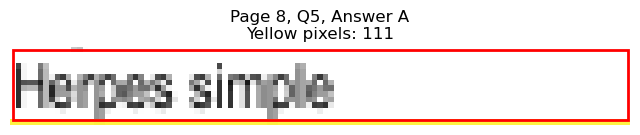

Page 8, Q5 - B: Detected box: x0=75.4, y0=329.2, x1=138.6, y1=341.9
Page 8, Q5, B: Yellow pixels: 1223
Page 8, Q5, B: Total non-white pixels: 1482
Page 8, Q5, B: Yellow percentage: 82.5%


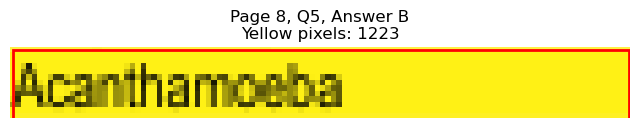

Page 8, Q5 - C: Detected box: x0=334.6, y0=316.6, x1=390.3, y1=329.3
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 281
Page 8, Q5, C: Yellow percentage: 0.0%


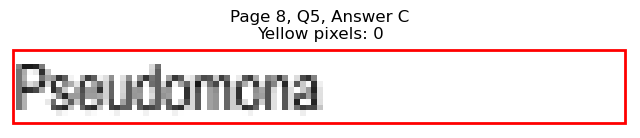

Page 8, Q5 - D: Detected box: x0=334.6, y0=329.2, x1=370.7, y1=341.9
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 192
Page 8, Q5, D: Yellow percentage: 0.0%


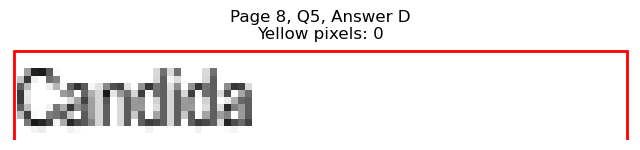


Page 8, Q5 - Selected Answer: B (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=75.4, y0=392.3, x1=230.0, y1=405.0
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 750
Page 8, Q6, A: Yellow percentage: 0.0%


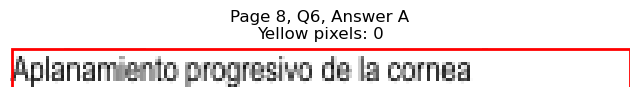

Page 8, Q6 - B: Detected box: x0=75.4, y0=404.9, x1=224.3, y1=417.6
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 763
Page 8, Q6, B: Yellow percentage: 0.0%


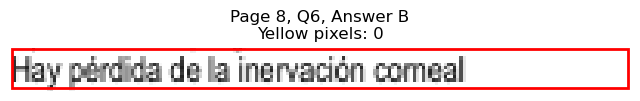

Page 8, Q6 - C: Detected box: x0=334.6, y0=392.3, x1=466.5, y1=405.0
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 838
Page 8, Q6, C: Yellow percentage: 0.0%


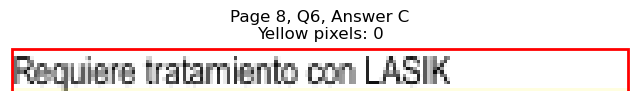

Page 8, Q6 - D: Detected box: x0=334.6, y0=404.9, x1=458.0, y1=417.6
Page 8, Q6, D: Yellow pixels: 1812
Page 8, Q6, D: Total non-white pixels: 2436
Page 8, Q6, D: Yellow percentage: 74.4%


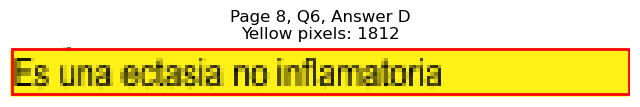


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=75.4, y0=442.8, x1=142.1, y1=455.5
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 320
Page 8, Q7, A: Yellow percentage: 0.0%


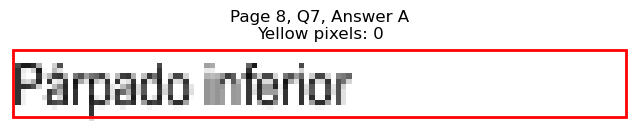

Page 8, Q7 - B: Detected box: x0=75.4, y0=455.5, x1=147.1, y1=468.1
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 351
Page 8, Q7, B: Yellow percentage: 0.0%


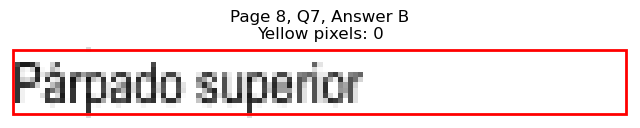

Page 8, Q7 - C: Detected box: x0=334.6, y0=442.8, x1=391.3, y1=455.5
Page 8, Q7, C: Yellow pixels: 1185
Page 8, Q7, C: Total non-white pixels: 1512
Page 8, Q7, C: Yellow percentage: 78.4%


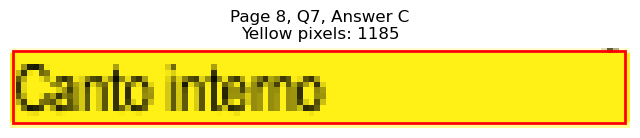

Page 8, Q7 - D: Detected box: x0=334.6, y0=455.5, x1=393.8, y1=468.1
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 280
Page 8, Q7, D: Yellow percentage: 0.0%


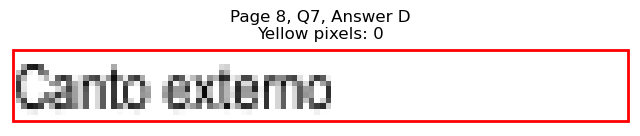


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=75.4, y0=531.2, x1=141.6, y1=543.8
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 436
Page 8, Q8, A: Yellow percentage: 0.0%


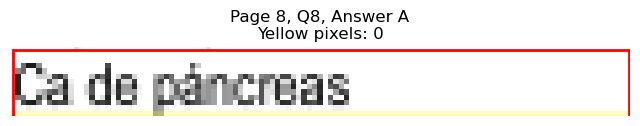

Page 8, Q8 - B: Detected box: x0=75.4, y0=543.8, x1=136.6, y1=556.4
Page 8, Q8, B: Yellow pixels: 1216
Page 8, Q8, B: Total non-white pixels: 1568
Page 8, Q8, B: Yellow percentage: 77.6%


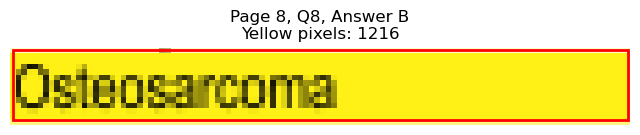

Page 8, Q8 - C: Detected box: x0=334.6, y0=531.2, x1=385.3, y1=543.8
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 231
Page 8, Q8, C: Yellow percentage: 0.0%


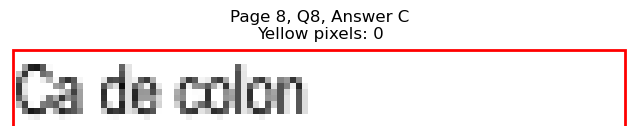

Page 8, Q8 - D: Detected box: x0=334.6, y0=543.8, x1=398.3, y1=556.4
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 340
Page 8, Q8, D: Yellow percentage: 0.0%


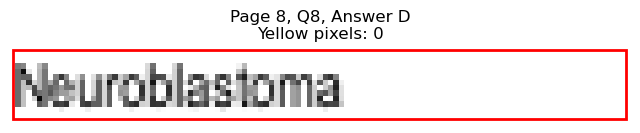


Page 8, Q8 - Selected Answer: B (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=75.4, y0=581.7, x1=195.3, y1=594.4
Page 8, Q9, A: Yellow pixels: 1583
Page 8, Q9, A: Total non-white pixels: 2394
Page 8, Q9, A: Yellow percentage: 66.1%


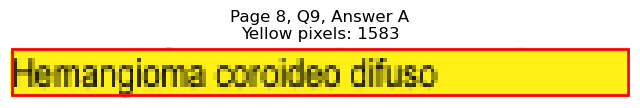

Page 8, Q9 - B: Detected box: x0=75.4, y0=594.3, x1=193.2, y1=607.0
Page 8, Q9, B: Yellow pixels: 1
Page 8, Q9, B: Total non-white pixels: 767
Page 8, Q9, B: Yellow percentage: 0.1%


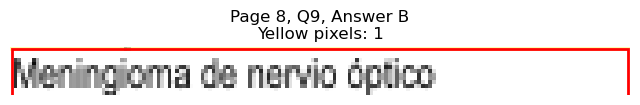

Page 8, Q9 - C: Detected box: x0=334.6, y0=581.7, x1=462.5, y1=594.4
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 659
Page 8, Q9, C: Yellow percentage: 0.0%


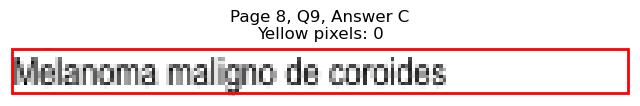

Page 8, Q9 - D: Detected box: x0=334.6, y0=594.3, x1=404.8, y1=607.0
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 389
Page 8, Q9, D: Yellow percentage: 0.0%


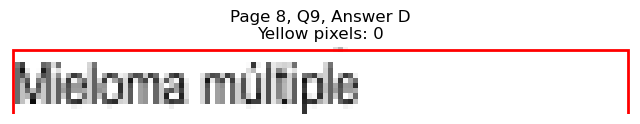


Page 8, Q9 - Selected Answer: A (based on yellow pixel count)




Page 8, Q10 - A: Detected box: x0=75.4, y0=632.2, x1=206.3, y1=644.9
Page 8, Q10, A: Yellow pixels: 0
Page 8, Q10, A: Total non-white pixels: 661
Page 8, Q10, A: Yellow percentage: 0.0%


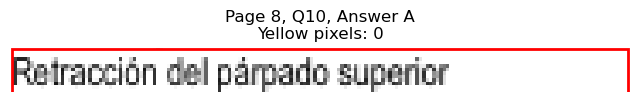

Page 8, Q10 - B: Detected box: x0=75.4, y0=644.9, x1=153.6, y1=657.5
Page 8, Q10, B: Yellow pixels: 0
Page 8, Q10, B: Total non-white pixels: 375
Page 8, Q10, B: Yellow percentage: 0.0%


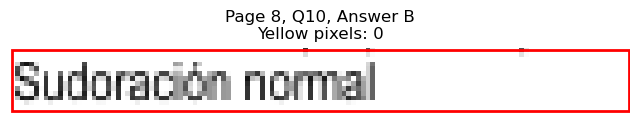

Page 8, Q10 - C: Detected box: x0=334.6, y0=632.2, x1=424.4, y1=644.9
Page 8, Q10, C: Yellow pixels: 1517
Page 8, Q10, C: Total non-white pixels: 1833
Page 8, Q10, C: Yellow percentage: 82.8%


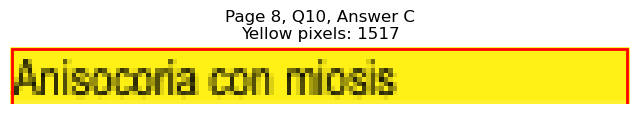

Page 8, Q10 - D: Detected box: x0=334.6, y0=644.9, x1=411.9, y1=657.5
Page 8, Q10, D: Yellow pixels: 0
Page 8, Q10, D: Total non-white pixels: 425
Page 8, Q10, D: Yellow percentage: 0.0%


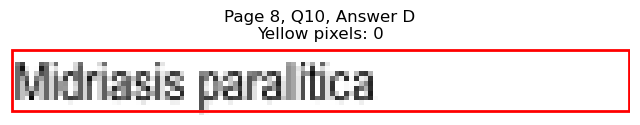


Page 8, Q10 - Selected Answer: C (based on yellow pixel count)




Page 8, Q11 - A: Detected box: x0=75.4, y0=682.7, x1=133.6, y1=695.3
Page 8, Q11, A: Yellow pixels: 0
Page 8, Q11, A: Total non-white pixels: 308
Page 8, Q11, A: Yellow percentage: 0.0%


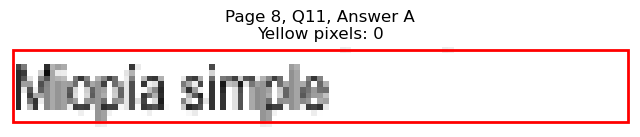

Page 8, Q11 - B: Detected box: x0=75.4, y0=695.4, x1=132.0, y1=708.0
Page 8, Q11, B: Yellow pixels: 0
Page 8, Q11, B: Total non-white pixels: 295
Page 8, Q11, B: Yellow percentage: 0.0%


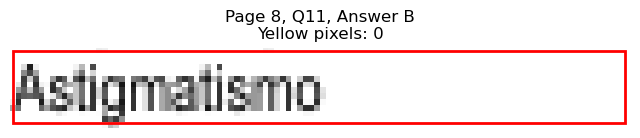

Page 8, Q11 - C: Detected box: x0=334.6, y0=682.7, x1=394.3, y1=695.3
Page 8, Q11, C: Yellow pixels: 1062
Page 8, Q11, C: Total non-white pixels: 1554
Page 8, Q11, C: Yellow percentage: 68.3%


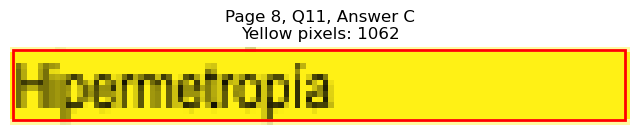

Page 8, Q11 - D: Detected box: x0=334.6, y0=695.4, x1=382.3, y1=708.0
Page 8, Q11, D: Yellow pixels: 2
Page 8, Q11, D: Total non-white pixels: 328
Page 8, Q11, D: Yellow percentage: 0.6%


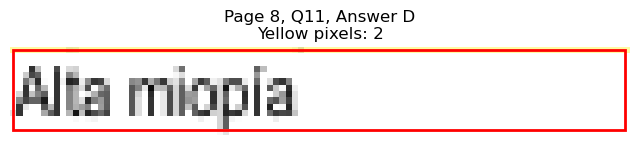


Page 8, Q11 - Selected Answer: C (based on yellow pixel count)




Page 8, Q12 - A: Detected box: x0=75.4, y0=733.2, x1=106.0, y1=745.8
Page 8, Q12, A: Yellow pixels: 0
Page 8, Q12, A: Total non-white pixels: 221
Page 8, Q12, A: Yellow percentage: 0.0%


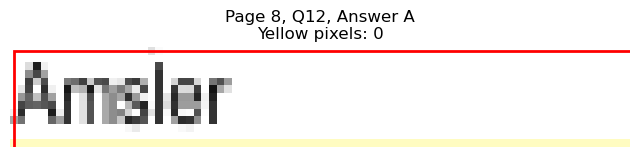

Page 8, Q12 - B: Detected box: x0=75.4, y0=745.8, x1=123.0, y1=758.4
Page 8, Q12, B: Yellow pixels: 1094
Page 8, Q12, B: Total non-white pixels: 1386
Page 8, Q12, B: Yellow percentage: 78.9%


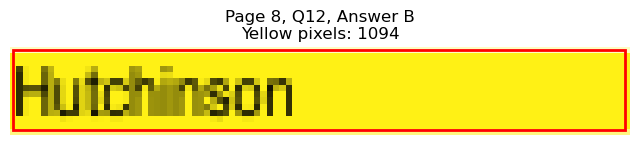

Page 8, Q12 - C: Detected box: x0=334.6, y0=733.2, x1=362.7, y1=745.8
Page 8, Q12, C: Yellow pixels: 0
Page 8, Q12, C: Total non-white pixels: 146
Page 8, Q12, C: Yellow percentage: 0.0%


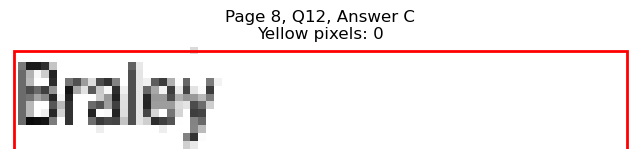

Page 8, Q12 - D: Detected box: x0=334.6, y0=745.8, x1=374.2, y1=758.4
Page 8, Q12, D: Yellow pixels: 0
Page 8, Q12, D: Total non-white pixels: 208
Page 8, Q12, D: Yellow percentage: 0.0%


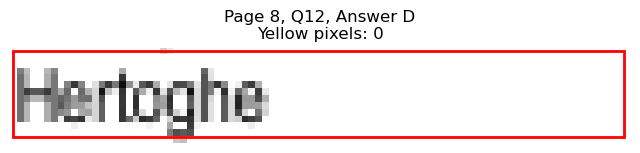


Page 8, Q12 - Selected Answer: B (based on yellow pixel count)





Page 9: Found 11 questions
Page 9, Q1 - A: Detected box: x0=75.4, y0=102.0, x1=169.7, y1=114.7
Page 9, Q1, A: Yellow pixels: 1495
Page 9, Q1, A: Total non-white pixels: 1885
Page 9, Q1, A: Yellow percentage: 79.3%


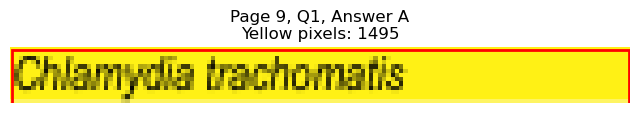

Page 9, Q1 - B: Detected box: x0=75.4, y0=114.6, x1=189.7, y1=127.3
Page 9, Q1, B: Yellow pixels: 164
Page 9, Q1, B: Total non-white pixels: 751
Page 9, Q1, B: Yellow percentage: 21.8%


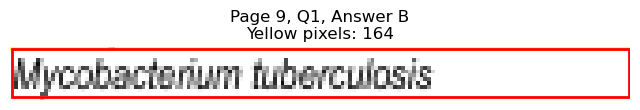

Page 9, Q1 - C: Detected box: x0=334.6, y0=102.0, x1=428.5, y1=114.7
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 486
Page 9, Q1, C: Yellow percentage: 0.0%


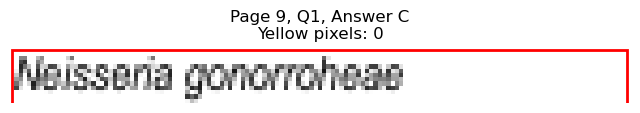

Page 9, Q1 - D: Detected box: x0=334.6, y0=114.6, x1=412.4, y1=127.3
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 423
Page 9, Q1, D: Yellow percentage: 0.0%


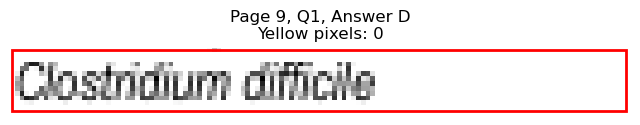


Page 9, Q1 - Selected Answer: A (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=75.4, y0=152.5, x1=351.8, y1=165.2
Page 9, Q2, A: Yellow pixels: 3213
Page 9, Q2, A: Total non-white pixels: 4578
Page 9, Q2, A: Yellow percentage: 70.2%


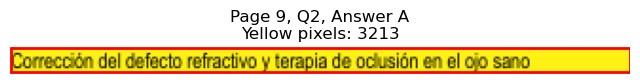

Page 9, Q2 - B: Detected box: x0=75.4, y0=165.1, x1=272.6, y1=177.8
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 1225
Page 9, Q2, B: Yellow percentage: 0.0%


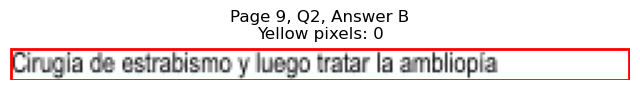

Page 9, Q2 - C: Detected box: x0=75.9, y0=177.7, x1=280.0, y1=190.4
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 1064
Page 9, Q2, C: Yellow percentage: 0.0%


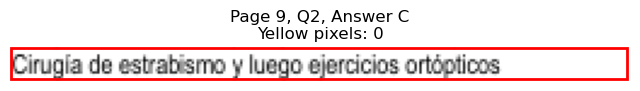

Page 9, Q2 - D: Detected box: x0=75.9, y0=190.3, x1=369.3, y1=203.0
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 1438
Page 9, Q2, D: Yellow percentage: 0.0%


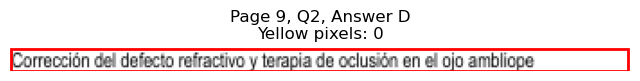


Page 9, Q2 - Selected Answer: A (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=75.4, y0=253.5, x1=95.9, y1=266.1
Page 9, Q3, A: Yellow pixels: 858
Page 9, Q3, A: Total non-white pixels: 994
Page 9, Q3, A: Yellow percentage: 86.3%


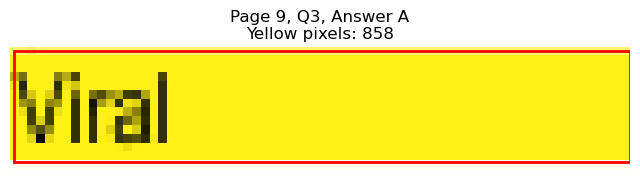

Page 9, Q3 - B: Detected box: x0=75.4, y0=266.1, x1=110.5, y1=278.7
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 262
Page 9, Q3, B: Yellow percentage: 0.0%


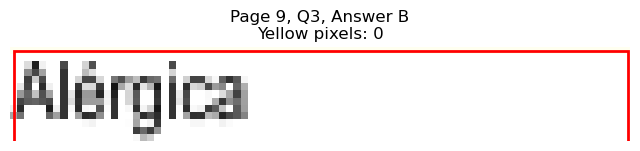

Page 9, Q3 - C: Detected box: x0=334.6, y0=253.5, x1=380.3, y1=266.1
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 238
Page 9, Q3, C: Yellow percentage: 0.0%


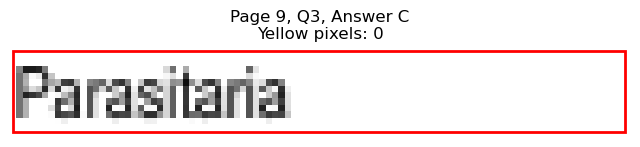

Page 9, Q3 - D: Detected box: x0=334.6, y0=266.1, x1=370.4, y1=278.7
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 198
Page 9, Q3, D: Yellow percentage: 0.0%


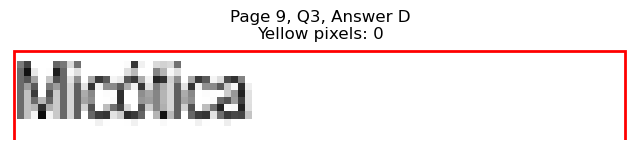


Page 9, Q3 - Selected Answer: A (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=75.4, y0=304.0, x1=105.0, y1=316.7
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 146
Page 9, Q4, A: Yellow percentage: 0.0%


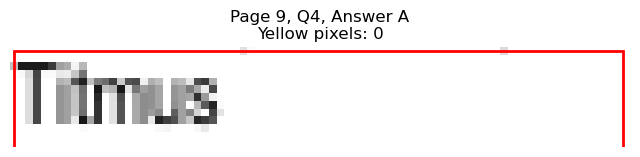

Page 9, Q4 - B: Detected box: x0=75.4, y0=316.6, x1=101.9, y1=329.3
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 124
Page 9, Q4, B: Yellow percentage: 0.0%


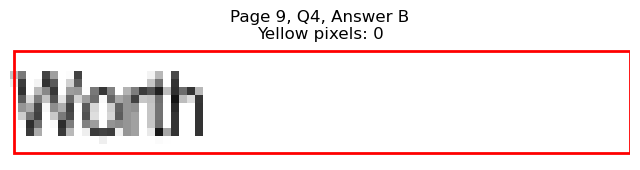

Page 9, Q4 - C: Detected box: x0=334.6, y0=304.0, x1=369.2, y1=316.7
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 266
Page 9, Q4, C: Yellow percentage: 0.0%


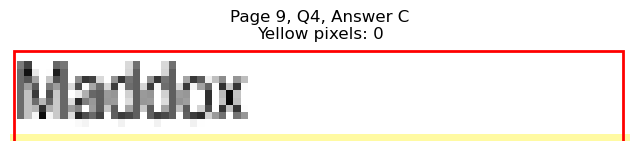

Page 9, Q4 - D: Detected box: x0=334.6, y0=316.6, x1=369.2, y1=329.3
Page 9, Q4, D: Yellow pixels: 902
Page 9, Q4, D: Total non-white pixels: 1204
Page 9, Q4, D: Yellow percentage: 74.9%


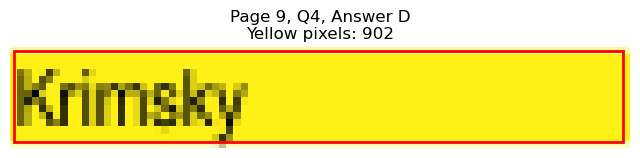


Page 9, Q4 - Selected Answer: D (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=75.4, y0=354.5, x1=184.2, y1=367.2
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 548
Page 9, Q5, A: Yellow percentage: 0.0%


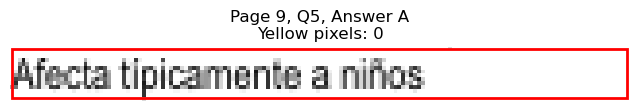

Page 9, Q5 - B: Detected box: x0=91.6, y0=367.1, x1=134.1, y1=379.8
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 414
Page 9, Q5, B: Yellow percentage: 0.0%


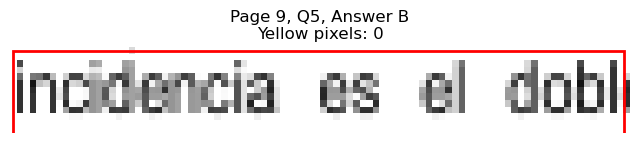

Page 9, Q5 - C: Detected box: x0=334.6, y0=354.5, x1=477.6, y1=367.2
Page 9, Q5, C: Yellow pixels: 194
Page 9, Q5, C: Total non-white pixels: 901
Page 9, Q5, C: Yellow percentage: 21.5%


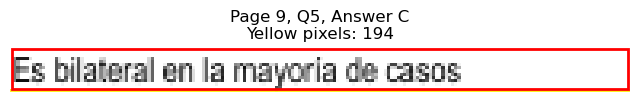

Page 9, Q5 - D: Detected box: x0=334.6, y0=367.1, x1=511.2, y1=379.8
Page 9, Q5, D: Yellow pixels: 2011
Page 9, Q5, D: Total non-white pixels: 2691
Page 9, Q5, D: Yellow percentage: 74.7%


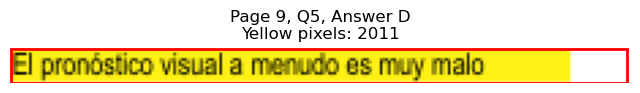


Page 9, Q5 - Selected Answer: D (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=75.4, y0=430.2, x1=129.5, y1=442.9
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 275
Page 9, Q6, A: Yellow percentage: 0.0%


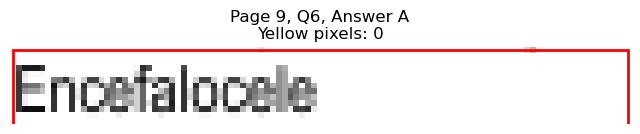

Page 9, Q6 - B: Detected box: x0=75.4, y0=442.8, x1=126.0, y1=455.5
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 261
Page 9, Q6, B: Yellow percentage: 0.0%


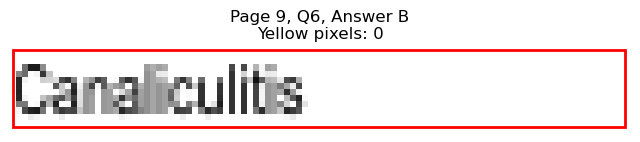

Page 9, Q6 - C: Detected box: x0=334.6, y0=430.2, x1=419.9, y1=442.9
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 579
Page 9, Q6, C: Yellow percentage: 0.0%


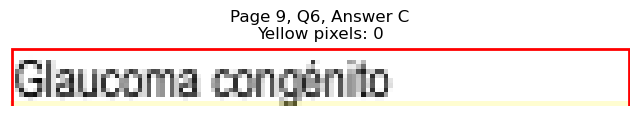

Page 9, Q6 - D: Detected box: x0=334.6, y0=442.8, x1=421.4, y1=455.5
Page 9, Q6, D: Yellow pixels: 1443
Page 9, Q6, D: Total non-white pixels: 1932
Page 9, Q6, D: Yellow percentage: 74.7%


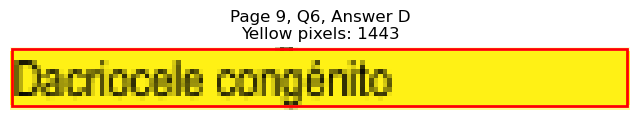


Page 9, Q6 - Selected Answer: D (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=75.4, y0=480.8, x1=339.8, y1=493.4
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 1307
Page 9, Q7, A: Yellow percentage: 0.0%


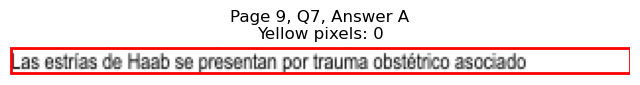

Page 9, Q7 - B: Detected box: x0=75.4, y0=493.4, x1=223.4, y1=506.0
Page 9, Q7, B: Yellow pixels: 199
Page 9, Q7, B: Total non-white pixels: 1077
Page 9, Q7, B: Yellow percentage: 18.5%


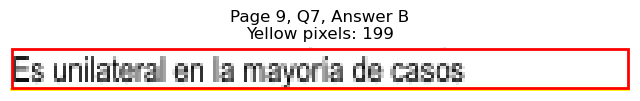

Page 9, Q7 - C: Detected box: x0=75.9, y0=506.0, x1=328.1, y1=518.6
Page 9, Q7, C: Yellow pixels: 3004
Page 9, Q7, C: Total non-white pixels: 4256
Page 9, Q7, C: Yellow percentage: 70.6%


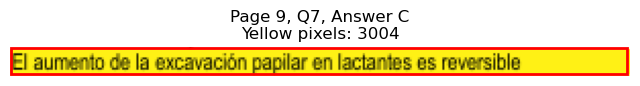

Page 9, Q7 - D: Detected box: x0=75.9, y0=518.6, x1=243.4, y1=531.2
Page 9, Q7, D: Yellow pixels: 219
Page 9, Q7, D: Total non-white pixels: 1059
Page 9, Q7, D: Yellow percentage: 20.7%


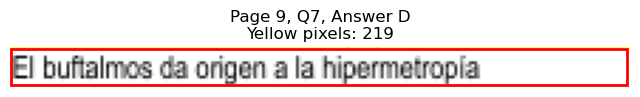


Page 9, Q7 - Selected Answer: C (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=75.4, y0=556.5, x1=163.1, y1=569.2
Page 9, Q8, A: Yellow pixels: 139
Page 9, Q8, A: Total non-white pixels: 602
Page 9, Q8, A: Yellow percentage: 23.1%


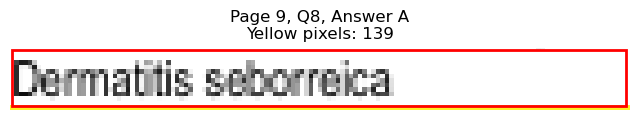

Page 9, Q8 - B: Detected box: x0=75.4, y0=569.1, x1=133.1, y1=581.8
Page 9, Q8, B: Yellow pixels: 1198
Page 9, Q8, B: Total non-white pixels: 1417
Page 9, Q8, B: Yellow percentage: 84.5%


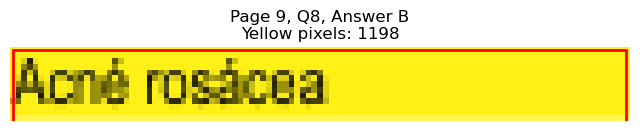

Page 9, Q8 - C: Detected box: x0=334.6, y0=556.5, x1=409.4, y1=569.2
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 397
Page 9, Q8, C: Yellow percentage: 0.0%


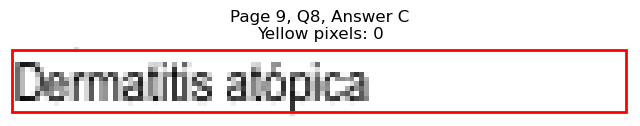

Page 9, Q8 - D: Detected box: x0=334.6, y0=569.1, x1=364.3, y1=581.8
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 157
Page 9, Q8, D: Yellow percentage: 0.0%


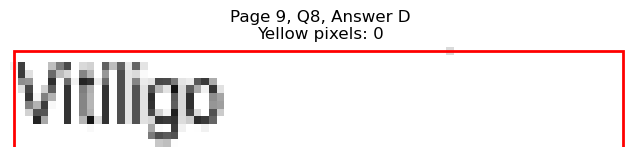


Page 9, Q8 - Selected Answer: B (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=75.4, y0=619.6, x1=179.7, y1=632.3
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 519
Page 9, Q9, A: Yellow percentage: 0.0%


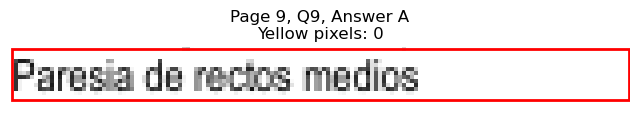

Page 9, Q9 - B: Detected box: x0=75.4, y0=632.2, x1=193.7, y1=644.9
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 606
Page 9, Q9, B: Yellow percentage: 0.0%


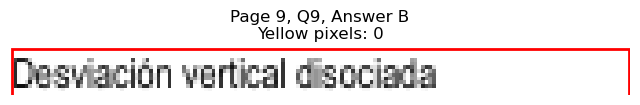

Page 9, Q9 - C: Detected box: x0=334.6, y0=619.6, x1=422.5, y1=632.3
Page 9, Q9, C: Yellow pixels: 1319
Page 9, Q9, C: Total non-white pixels: 1946
Page 9, Q9, C: Yellow percentage: 67.8%


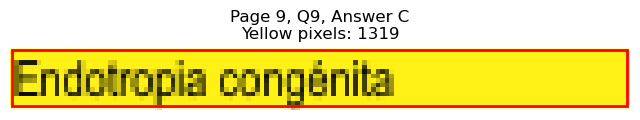

Page 9, Q9 - D: Detected box: x0=334.6, y0=632.2, x1=434.5, y1=644.9
Page 9, Q9, D: Yellow pixels: 0
Page 9, Q9, D: Total non-white pixels: 656
Page 9, Q9, D: Yellow percentage: 0.0%


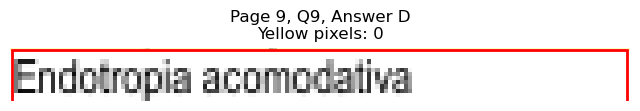


Page 9, Q9 - Selected Answer: C (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=75.4, y0=670.1, x1=190.2, y1=682.7
Page 9, Q10, A: Yellow pixels: 0
Page 9, Q10, A: Total non-white pixels: 742
Page 9, Q10, A: Yellow percentage: 0.0%


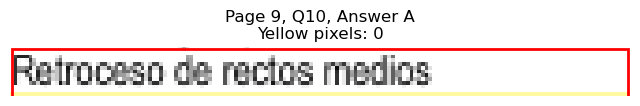

Page 9, Q10 - B: Detected box: x0=75.4, y0=682.7, x1=195.3, y1=695.3
Page 9, Q10, B: Yellow pixels: 1571
Page 9, Q10, B: Total non-white pixels: 2394
Page 9, Q10, B: Yellow percentage: 65.6%


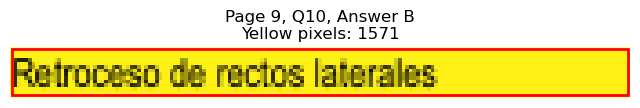

Page 9, Q10 - C: Detected box: x0=334.6, y0=670.1, x1=472.1, y1=682.7
Page 9, Q10, C: Yellow pixels: 0
Page 9, Q10, C: Total non-white pixels: 702
Page 9, Q10, C: Yellow percentage: 0.0%


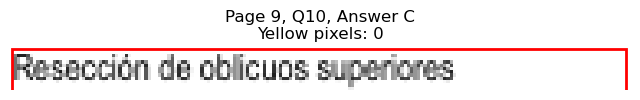

Page 9, Q10 - D: Detected box: x0=334.6, y0=682.7, x1=467.0, y1=695.3
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 661
Page 9, Q10, D: Yellow percentage: 0.0%


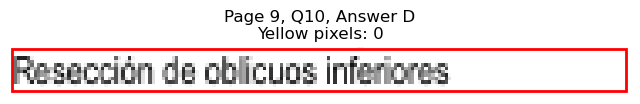


Page 9, Q10 - Selected Answer: B (based on yellow pixel count)




Page 9, Q11 - A: Detected box: x0=75.4, y0=745.8, x1=227.3, y1=758.4
Page 9, Q11, A: Yellow pixels: 0
Page 9, Q11, A: Total non-white pixels: 815
Page 9, Q11, A: Yellow percentage: 0.0%


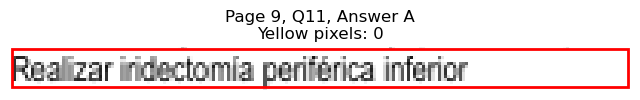

Page 9, Q11 - B: Detected box: x0=75.4, y0=758.5, x1=216.3, y1=771.2
Page 9, Q11, B: Yellow pixels: 1961
Page 9, Q11, B: Total non-white pixels: 2688
Page 9, Q11, B: Yellow percentage: 73.0%


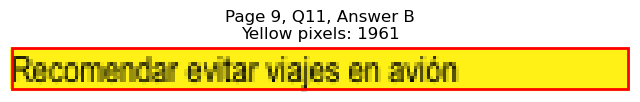

Page 9, Q11 - C: Detected box: x0=334.6, y0=745.8, x1=485.0, y1=758.4
Page 9, Q11, C: Yellow pixels: 0
Page 9, Q11, C: Total non-white pixels: 779
Page 9, Q11, C: Yellow percentage: 0.0%


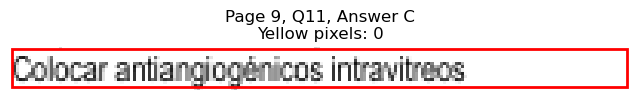

Page 9, Q11 - D: Detected box: x0=334.6, y0=758.5, x1=466.5, y1=771.2
Page 9, Q11, D: Yellow pixels: 0
Page 9, Q11, D: Total non-white pixels: 664
Page 9, Q11, D: Yellow percentage: 0.0%


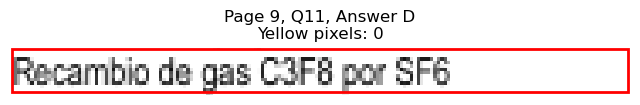


Page 9, Q11 - Selected Answer: B (based on yellow pixel count)





Page 10: Found 1 questions
Page 10, Q1 - A: Detected box: x0=75.4, y0=89.4, x1=114.5, y1=102.1
Page 10, Q1, A: Yellow pixels: 90
Page 10, Q1, A: Total non-white pixels: 282
Page 10, Q1, A: Yellow percentage: 31.9%


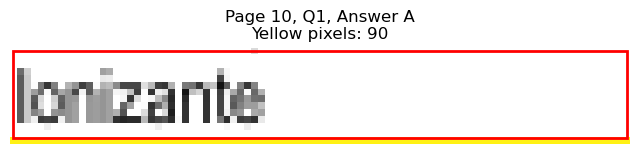

Page 10, Q1 - B: Detected box: x0=75.4, y0=102.0, x1=114.0, y1=114.7
Page 10, Q1, B: Yellow pixels: 1019
Page 10, Q1, B: Total non-white pixels: 1170
Page 10, Q1, B: Yellow percentage: 87.1%


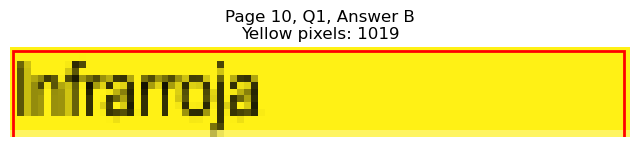

Page 10, Q1 - C: Detected box: x0=334.6, y0=89.4, x1=390.8, y1=102.1
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 288
Page 10, Q1, C: Yellow percentage: 0.0%


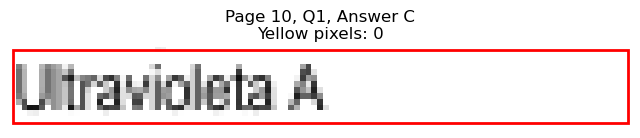

Page 10, Q1 - D: Detected box: x0=334.6, y0=102.0, x1=388.4, y1=114.7
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 295
Page 10, Q1, D: Yellow percentage: 0.0%


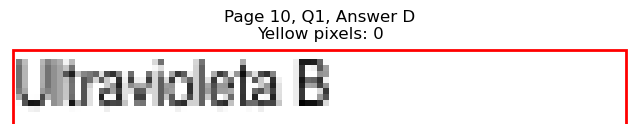


Page 10, Q1 - Selected Answer: B (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,¿Cuál es la enfermedad que se presenta con art...
1,¿Cuál es la alteración que se presenta en el s...
2,¿Qué caracteriza a la coriorretinopatía serosa...
3,Niña de 12 años con baja visión de OD. Anteced...
4,"Varón de 40 años, con infarto del lóbulo parie..."
...,...
95,¿Cuál es la enfermedad cutánea que comúnmente ...
96,"Niño de 1 año, presenta endotropia de ángulo a..."
97,¿Cuál es la cirugía que se indica en el tratam...
98,"Varón de 50 años, con desprendimiento total de..."


In [8]:
answers_df

,option_A,option_B,option_C,option_D
0,Ehlers-Danlos,Hudson-Stähli,Tolosa-Hunt,Von Hippel-Lindau
1,Insuficiencia de convergencia,Restricción de la abducción,Déficit de elevación en aducción,Estrechamiento de la hendidura palpebral
2,Desprendimiento de retina regmatógeno,Desprendimiento coroideo seroso peripapilar,Agujero macular con desprendimiento seroso de ...,Desprendimiento de la retina neurosensorial en...
3,Toxoplasmosis,Toxocariasis,Retinoblastoma,Tuberculosis
4,Nasal superior,Temporal inferior,Nasal inferior,Temporal superior
...,...,...,...,...
95,Dermatitis seborreica,Acné rosácea,Dermatitis atópica,Vitíligo
96,Paresia de rectos medios,Desviación vertical disociada,Endotropia congénita,Endotropia acomodativa
97,Retroceso de rectos medios,Retroceso de rectos laterales,Resección de oblicuos superiores,Resección de oblicuos inferiores
98,Realizar iridectomía periférica inferior,Recomendar evitar viajes en avión,Colocar antiangiogénicos intravitreos,Recambio de gas C3F8 por SF6


In [9]:
correct_answers_df

,correct_answer
0,A
1,C
2,D
3,B
4,B
...,...
95,B
96,C
97,B
98,B


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,correct_answer
0,¿Cuál es la enfermedad que se presenta con art...,Ehlers-Danlos,Hudson-Stähli,Tolosa-Hunt,Von Hippel-Lindau,A
1,¿Cuál es la alteración que se presenta en el s...,Insuficiencia de convergencia,Restricción de la abducción,Déficit de elevación en aducción,Estrechamiento de la hendidura palpebral,C
2,¿Qué caracteriza a la coriorretinopatía serosa...,Desprendimiento de retina regmatógeno,Desprendimiento coroideo seroso peripapilar,Agujero macular con desprendimiento seroso de ...,Desprendimiento de la retina neurosensorial en...,D
3,Niña de 12 años con baja visión de OD. Anteced...,Toxoplasmosis,Toxocariasis,Retinoblastoma,Tuberculosis,B
4,"Varón de 40 años, con infarto del lóbulo parie...",Nasal superior,Temporal inferior,Nasal inferior,Temporal superior,B
...,...,...,...,...,...,...
95,¿Cuál es la enfermedad cutánea que comúnmente ...,Dermatitis seborreica,Acné rosácea,Dermatitis atópica,Vitíligo,B
96,"Niño de 1 año, presenta endotropia de ángulo a...",Paresia de rectos medios,Desviación vertical disociada,Endotropia congénita,Endotropia acomodativa,C
97,¿Cuál es la cirugía que se indica en el tratam...,Retroceso de rectos medios,Retroceso de rectos laterales,Resección de oblicuos superiores,Resección de oblicuos inferiores,B
98,"Varón de 50 años, con desprendimiento total de...",Realizar iridectomía periférica inferior,Recomendar evitar viajes en avión,Colocar antiangiogénicos intravitreos,Recambio de gas C3F8 por SF6,B


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/OFTALMOLOGÍA.csv
